# Predicting how temperature shifts code ideas: a frozen two-decision law (claim L, iteration 8)

**Question.** When an instruction-tuned LLM writes a program for a task with several textbook solutions (BFS or DFS for a grid path, Kruskal or Prim for a minimum spanning tree, a linear scan or binary search, ...), the *idea* it implements changes with the sampling temperature $T$. Is temperature a "creativity knob" that adds new ideas, or does it only re-weight a few known ones? This experiment tests a sharp, pre-registered claim:

> **Claim L.** A frozen law over one or two *decision tokens*, located blindly in the model's own generations, predicts the distribution of attempted algorithms at $T$ = 0.3 / 0.7 / 1.0 / 1.3 (top-p 1 and top-k 10, N = 100 same-stream programs per cell) **before any temperature sample is drawn**.

**The law** (per prompt template $w$, sampler $\kappa \in$ {top-p 1, top-k 10}, temperature $T$):

- $\pi_T(t \mid \text{prefix}) = \mathrm{softmax}(z/T)$, renormalised over the 10 largest logits for top-k 10
- $w_T(O) = \prod_i \pi_T(o_i \mid \text{prefix}, o_{<i})$: the probability of staying on an *opening* $O$ (the $d$ generated tokens before the decision token)
- $F_T(c, A) = \sum_{t_1 \in \text{top-20}} \pi_T(t_1 \mid O_c)\, G_T(t_1, A) + r_T(c)\, \hat P(A \mid \text{resid}_c)$, where $G_T(t_1, A) = \hat P(A \mid t_1)$, or, if a second decision token $t_2$ sits inside the $t_1$ branch, the same mix one level down
- $P_T(A \mid w) = \sum_c w_T(O_c)\, F_T(c, A) + \big(1 - \sum_c w_T(O_c)\big)\, q_\text{rest}(A)$; a cell's prediction is the mean over the 5 templates.

$\hat P(A \mid t)$, the algorithm a program ends up implementing after decision token $t$, is estimated once at $T = 1$ from forced continuations; temperature enters **only** through the model's own token probabilities at the decision point. **Rivals:** B0 flat (fit-twin shares at every $T$), B1 algorithm-level tempering $q^{1/T}$, B2 the single-decision law, BH the same law at the maximum-entropy position instead of the located decision token. **Score:** $\text{MAE}_u$ = mean over the four temperatures of the total-variation distance between the predicted and observed label distributions. A unit passes with MAE $\le$ 0.10 and $H(A \mid \text{decision classes}) \le$ 0.3 bits.

**Units scored** (task x model, 5 prompt templates each):

| unit | model | task | algorithm catalogue | role |
|---|---|---|---|---|
| A3 | Qwen3-8B | trapped rain water | two_pointers, prefix_suffix_max, monotonic_stack, peak_split | law development |
| B6 | Qwen3-8B | valid anagram | sort_compare, hash_count, fixed_count_array | law development |
| B3 | Qwen3-8B | minimum spanning tree weight | kruskal, prim_heap, prim_array, boruvka | law development |
| G-T04 | gemma-3-4b-it | substring search | naive, kmp, rabin_karp, z_algorithm, bmh, builtin | held out |
| G-R6 | gemma-3-4b-it | first and last position | binary_search, bisect_module, exponential_search, linear_scan | held out |
| L-T1 | Llama-3.1-8B-Instruct | grid path | bfs, dfs, bibfs, astar_gbfs, dijkstra, iddfs | held out |

**What `method.py` runs** (15 stages, about 5 h on one 20 GB RTX A4500): (1) GPU, per unit: fit twins at $T = 1$; a blind locator that resamples continuations from prefixes of base programs to find where the algorithm gets decided; forced-token continuations for $\hat P$; teacher forcing of every opening under all 5 templates. (2) Commit the predictions in a hash chain *before* any sweep sample. (3) GPU sweep: 100 same-stream programs per cell. (4) CPU: labelling, scoring, rivals, placebos, verdict, figures.

**What this notebook re-runs (CPU only, under a minute):** everything downstream of teacher forcing. That is the law's unit tests; the law and its four rivals evaluated on the committed teacher-forced quantities (checked against the committed predictions); the committed scoring against the observed sweep counts (MAE, placebos, Newcombe intervals, verdict); slot-level checks on 90 curated same-stream slots (replay accuracy, McNemar drop test, ideas vs phrasings); and the paper's figures F1 to F4 and F6. Sampling and teacher forcing of the 4 to 8B-parameter models are not re-run: they need a 20 GB GPU and hours. Their outputs enter through `mini_demo_data.json`.

**Committed result:** claim L is **PARTIAL**. 5 of 6 units pass (MAE: A3 0.029, B6 0.054, B3 0.043, G-T04 0.033, G-R6 0.014); L-T1 fails (0.142). Only 3 held-out units were scored (4 required), so the held-out criterion is underpowered; there is no disconfirmation.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the original scoring code logs with it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, pandas — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# original import block of src/analysis_L.py (the committed scoring)
import ast
import itertools
import math
import sys
from collections import Counter
from typing import Any

import numpy as np
from loguru import logger
from scipy.stats import binomtest, fisher_exact

# src/figures8.py (its matplotlib.use("Agg") is dropped so figures render inline)
import matplotlib.pyplot as plt

# notebook additions
import json
import re                  # src/opening_cls.py: code_part
import time
import warnings

import pandas as pd


# src/cfg8.py setup_logging(), without its rotating log-file sink
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")


setup_logging("analysis_L")

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-8/experiment-43/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
META = data["metadata"]                       # committed law inputs, observed cell counts, committed results
EXAMPLES = data["datasets"][0]["examples"]    # law_sweep: 90 curated same-stream slots
print(META["title"])
print("units:", ", ".join(META["units"]), "| law_sweep examples:", len(EXAMPLES))
print({k: v for k, v in EXAMPLES[0].items() if k not in ("metadata_cells", "metadata_replay")})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Predicting how temperature shifts code ideas (claim L, iteration 8): demo subset
units: A3, B6, B3, G-T04, G-R6, L-T1 | law_sweep examples: 90
{'input': '[A3 W1 slot 0] Do not use garlic for this task. . . . .', 'output': 'two_pointers', 'metadata_unit': 'A3', 'metadata_family': 'qwen', 'metadata_template': 'W1', 'metadata_slot': 0, 'metadata_held_out': False, 'metadata_seed': 16059802269865454861, 'predict_T0_3_p1': 'prefix_suffix_max|pass', 'predict_T0_3_k10': 'prefix_suffix_max|pass', 'predict_replay_T0_3': 'prefix_suffix_max', 'predict_law_L_prob_observed_T0_3': '0.8371', 'predict_T0_7_p1': 'two_pointers|pass', 'predict_T0_7_k10': 'two_pointers|pass', 'predict_replay_T0_7': 'prefix_suffix_max', 'predict_law_L_prob_observed_T0_7': '0.2789', 'predict_T1_0_p1': 'two_pointers|pass', 'predict_T1_0_k10': 'two_pointers|pass', 'predict_replay_T1_0': 'two_pointers', 'predict_law_L_prob_observed_T1_0': '0.306

## Configuration

The design constants are copied from `src/cfg8.py`; the pre-registered protocol fixes them. The tunable values are the sizes of the CPU-side checks: the unit tests, the placebo and bootstrap repeats, and the units and curated slots to score. They are set to the experiment's original values (noted in the comments), because the whole notebook runs in well under a minute on CPU. The GPU stages (model sampling and teacher forcing) cannot be scaled up here; their outputs enter through `mini_demo_data.json`.

In [5]:
# ---- design constants (src/cfg8.py; fixed by the pre-registered protocol) ----
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
TEMPS = (0.3, 0.7, 1.0, 1.3)
SAMPLERS = {"p1": 0, "k10": 10}                  # top-p 1 (full softmax) and top-k 10
BOOT_SEED = 20261023
THRESH = {
    "unit_mae_pass": 0.10, "unit_H_bits_pass": 0.3, "claim_frac_pass": 0.70, "heldout_pass_min": 3,
    "heldout_scored_min": 4, "disconfirm_mae": 0.20, "disconfirm_heldout_n": 3,
    "cp_pchange": 0.9, "cp_tv": 0.25, "refine_tv": 0.25, "class_phat_min": 0.7, "class_mass_min": 0.02,
    "second_trigger_mass": 0.05, "second_trigger_H": 0.3, "cluster_cov": 0.20, "max_clusters": 4,
    "oc_agree": 0.95, "consistency_tvd": 0.10, "calib_fisher_p": 0.05, "engine_agree": 0.95, "shadow_ident": 0.95,
    "regate_agree": 0.9, "other_adjudicate": 0.20, "base_margin_gain": 2.0, "base_phrasing_dH": 0.5,
}
UNITS = {u: U["spec"] for u, U in META["units"].items()}   # family, task, held_out, name, catalogue, model_id

# ---- tunable sizes of the CPU-side checks: set to the original values, which run in seconds on CPU ----
# (the notebook was first tested with RUN_UNITS = ["A3"], U10_N = 10, U11_N_U = 100, N_TEMP_SHUFFLE = 10,
#  N_TOKEN_MAP = 5, N_BOOT = 10, HILL_N_REP = 5, DEMO_SLOTS = (0,), then scaled up)
RUN_UNITS = ["A3", "B6", "B3", "G-T04", "G-R6", "L-T1"]   # original: ["A3", "B6", "B3", "G-T04", "G-R6", "L-T1"] (the six scored units)
U10_N = 1000                # original 1000: synthetic logit sequences in unit test U10 (top-k shadow)
U11_N_U = 10000             # original 10000: Monte Carlo uniform streams in unit test U11 (replay walk)
N_TEMP_SHUFFLE = 500        # original 500: temperature-label shuffles (placebo of the McNemar drop test)
N_TOKEN_MAP = 200           # original 200: token-map shuffles (placebo of the law)
N_BOOT = 1000               # original 1000 (cfg8.N_BOOT): slot-bootstrap replicates of the MAE differences
HILL_DEPTH = 25             # original 25: rarefaction depth of the correct-only Hill-1 diversity
HILL_N_REP = 200            # original 200: rarefaction repeats
PHRASING_J = 0.8            # original 0.8: AST 4-gram Jaccard threshold of one phrasing cluster
DEMO_SLOTS = (0, 7, 14)     # curated slots per template to use; the data holds (0, 7, 14) (original: slots 0-19)

## 1. The sampler transform (`src/replay.py`, unchanged)

Every program in the experiment was sampled with an exact, re-implementable transform:

1. $p = \mathrm{softmax}(z/T)$ in float64.
2. An optional top-k mask.
3. The cumulative sum **in token-id order**.
4. The first token whose CDF ≥ $u$, where $u$ is the slot's pre-drawn uniform for that step.

Every *slot* has its own uniform stream (seed = sha256 of the slot key), shared across all temperatures (common random numbers). The programs a slot writes at $T$ = 0.3 and at $T$ = 1.0 are therefore paired draws. `%%writefile` saves each module next to the notebook, so later code can `import replay` exactly as the original does.

In [6]:
%%writefile replay.py
#!/usr/bin/env python3
"""replay.pick(z, u, T, k): an independent float64 numpy re-implementation of the engine's per-step transform
(engine5.step_probs5 + engine_v4._inverse_cdf):
    p = softmax(z / T)                          (float64; z = the bf16 logits widened to float64)
    top-k: p[p < k-th largest p] = 0             (ties at the k-th value kept, exactly as the engine)
    cdf = cumsum(p) in TOKEN-ID order; cdf /= cdf[-1]
    token = first index with cdf >= u            (torch.searchsorted, right=False), clamped to V - 1
The token-id order makes the coupling across temperatures exact in marginals but NOT monotone in T, so per-slot
predictions must use pick(), never a sorted CDF.
"""

from __future__ import annotations

import numpy as np


def probs(z: np.ndarray, T: float, k: int = 0) -> np.ndarray:
    x = np.asarray(z, dtype=np.float64) / float(T)
    x = x - x.max()
    p = np.exp(x)
    p /= p.sum()
    if k and k > 0:
        kth = np.partition(p, -k)[-k]
        p = np.where(p < kth, 0.0, p)
    return p


def pick(z: np.ndarray, u: float, T: float, k: int = 0) -> int:
    p = probs(z, T, k)
    cdf = np.cumsum(p)
    cdf = cdf / cdf[-1]
    t = int(np.searchsorted(cdf, u, side="left"))
    return min(t, len(p) - 1)


def dist(z: np.ndarray, T: float, k: int = 0) -> np.ndarray:
    """The normalised sampling distribution of one step (kept mass renormalised)."""
    p = probs(z, T, k)
    return p / p.sum()

Overwriting replay.py


## 2. The iteration-7 prediction functions (`src/predict.py`, unchanged)

These are the one-decision law committed in iteration 7:

- `seq_logprob`: the probability of staying on an opening.
- `fork_mix`: the mix at a fork node.
- `binary_closed_form`: the closed form of a binary fork with margin $m$ nats, $P(\text{minority}) = 1/(1 + e^{m/T})$.

The intuition: at a decision token where the default algorithm leads by $m$ nats, cooling the sampler ($T \to 0$) suppresses the minority branch exponentially in $m/T$, and heating it ($T > 1$) flattens the fork towards 50/50. Unit tests U5 and U8 live here.

In [7]:
%%writefile predict.py
#!/usr/bin/env python3
"""Committed prediction functions (Part D4/D5), pure numpy over teacher-forced fp32 logits.

  pi_{T,kappa}(t | prefix) = softmax(z / T) over all tokens (kappa = full) or over the 10 largest logits (top10)
  w_{T,kappa}(c)   = prod_i pi_{T,kappa}(o_{c,i} | o_{c,<i})                       (probability of staying on O_c)
  F_{T,kappa}(c,A) = sum_t pi_{T,kappa}(t | O_c) Phat(A | O_c + t) + residual mass x Phat(A | residual bin)
  Phat_{T,kappa}(A) = sum_c w(c) F(c, A) + (1 - sum_c w(c)) q_rest(A)
Phat(A | t) is estimated from T = 1 continuations (the one-token concentration assumption carries it to other T).
"""

from __future__ import annotations

import math
from typing import Any

import numpy as np

import replay


def dist(z: np.ndarray, T: float, k: int) -> np.ndarray:
    return replay.dist(z, T, k)


def seq_logprob(Z: np.ndarray, toks: list[int], T: float, k: int) -> float:
    """sum_i log pi_{T,k}(toks[i] | row i of Z); -inf if a token is truncated away."""
    s = 0.0
    for z, t in zip(Z, toks):
        p = dist(z, T, k)[t]
        if p <= 0:
            return -math.inf
        s += math.log(p)
    return s


def fork_mix(z: np.ndarray, phat: dict[int, np.ndarray], resid: np.ndarray, T: float, k: int) -> dict[str, Any]:
    """F(c, .) at one fork node: expanded tokens use their own Phat, the remaining mass uses the residual bin."""
    p = dist(z, T, k)
    toks = list(phat)
    mass = np.array([p[t] for t in toks])
    F = np.zeros_like(resid, dtype=float)
    for m, t in zip(mass, toks):
        F += m * phat[t]
    rest = max(0.0, 1.0 - float(mass.sum()))
    F += rest * resid
    return {"F": F, "expanded_mass": float(mass.sum()), "residual_mass": rest}


def cell_prediction(clusters: list[dict[str, Any]], q_rest: np.ndarray, T: float, k: int) -> dict[str, Any]:
    """clusters: [{'Z_open': [len_O, V] logits predicting o_1..o_|O| (row i predicts o_i), 'O': ids,
    'z_fork': [V], 'phat': {tok: [C]}, 'resid': [C]}] for ONE template."""
    tot = np.zeros_like(q_rest, dtype=float)
    w_sum = 0.0
    parts = []
    for c in clusters:
        lw = seq_logprob(c["Z_open"], c["O"], T, k) if len(c["O"]) else 0.0
        w = math.exp(lw) if lw > -math.inf else 0.0
        fm = fork_mix(c["z_fork"], c["phat"], c["resid"], T, k)
        tot += w * fm["F"]
        w_sum += w
        parts.append({"w": w, "F": fm["F"].tolist(), "residual_mass": fm["residual_mass"]})
    w_sum = min(w_sum, 1.0)
    tot += (1.0 - w_sum) * q_rest
    return {"P": tot, "on_opening": w_sum, "parts": parts}


def binary_closed_form(m: float, T: float) -> float:
    """Minority probability of a binary fork with margin m nats at temperature T: 1 / (1 + exp(m / T))."""
    return 1.0 / (1.0 + math.exp(m / T))


def margin_nats(z: np.ndarray, d_tokens: list[int]) -> float:
    """m = log P_1(D-class tokens) - log P_1(non-D tokens) at T = 1."""
    p = dist(z, 1.0, 0)
    pd = float(sum(p[t] for t in d_tokens))
    pd = min(max(pd, 1e-300), 1.0)
    pn = max(1.0 - pd, 1e-300)
    return math.log(pd) - math.log(pn)


def u5_test() -> dict[str, Any]:
    """U5: synthetic binary fork with margin 0.575 nats and a fully shared opening."""
    V = 50
    z = np.full(V, -1e4)
    z[3], z[7] = 0.575, 0.0                   # D token 3, minority token 7
    phat = {3: np.array([1.0, 0.0]), 7: np.array([0.0, 1.0])}
    cl = [{"Z_open": np.zeros((0, V)), "O": [], "z_fork": z, "phat": phat, "resid": np.array([0.5, 0.5])}]
    got = {T: float(cell_prediction(cl, np.array([0.5, 0.5]), T, 0)["P"][1]) for T in (0.3, 1.0, 1.3)}
    want = {0.3: 0.128, 1.0: 0.36, 1.3: 0.391}
    # top-k 10 with the minority token at rank 11: 10 stronger tokens
    z2 = np.full(V, -1e4)
    z2[3], z2[7] = 0.575, 0.0
    for t in range(20, 30):
        z2[t] = 0.3
    phat2 = {3: np.array([1.0, 0.0]), 7: np.array([0.0, 1.0])} | {t: np.array([1.0, 0.0]) for t in range(20, 30)}
    cl2 = [{"Z_open": np.zeros((0, V)), "O": [], "z_fork": z2, "phat": phat2, "resid": np.array([0.5, 0.5])}]
    top10 = float(cell_prediction(cl2, np.array([0.5, 0.5]), 1.0, 10)["P"][1])
    ok = all(abs(got[T] - want[T]) < 0.0015 for T in want) and top10 == 0.0
    return {"got": got, "want": want, "closed_form": {T: binary_closed_form(0.575, T) for T in want},
            "top10_rank11_minority": top10, "pass": ok}


def u8_test() -> dict[str, Any]:
    """U8: path probability on a synthetic tree: two steps with known probabilities 0.2 and 0.5 -> 0.1."""
    V = 6
    z1 = np.log(np.array([0.2, 0.8, 1e-12, 1e-12, 1e-12, 1e-12]))
    z2 = np.log(np.array([0.5, 0.25, 0.25, 1e-12, 1e-12, 1e-12]))
    lp = seq_logprob(np.stack([z1, z2]), [0, 0], 1.0, 0)
    m = margin_nats(z1, [1])
    return {"path_prob": math.exp(lp), "want": 0.1, "margin": m, "margin_want": math.log(0.8 / 0.2),
            "pass": abs(math.exp(lp) - 0.1) < 1e-6 and abs(m - math.log(4)) < 1e-6}

Overwriting predict.py


## 3. The two-decision law (`src/predict8.py`, unchanged)

Iteration 8 adds one composition level: a second decision token inside a first-decision branch. On A3, for example, the token ` left` starts both `left = 0` (two pointers) and `left_max` (prefix/suffix maxima), and the second decision `' ='` vs `'_max'` settles it.

`cell_prediction(law, tf_by_w, T, sampler)` evaluates the law from **compact** teacher-forced quantities only. Per template, opening and (sampler, $T$), these are the log-probability of the opening, the probabilities of its 20 strongest decision tokens and the leftover mass, plus the same for each second decision. `b0` and `b1` are the flat and algorithm-tempered rivals and `mae` is the score. U9 to U11 are this module's unit tests.

In [8]:
%%writefile predict8.py
#!/usr/bin/env python3
"""predict8: iteration-7 predict.py (committed cell_prediction / fork_mix / seq_logprob, imported unchanged) plus ONE
composition level (a second decision token inside a first-decision branch), the committed baselines and the scoring
metric. Pure numpy; GPU-side teacher forcing reduces the logits to the compact inputs below.

The law (per template w, sampler kappa, temperature T):
  pi_{T,kappa}(t | prefix) = softmax(z / T) over all tokens, or renormalised over the 10 largest logits (top-k 10)
  w_T(O)        = prod_i pi_T(o_i | prefix, o_<i)
  G_T(t1, A)    = Phat(A | t1)                                                     (no second decision), else
                  w_T(O2 | t1) * [sum_{t2 in top10} pi_T(t2 | ..O2) Phat(A | t1, t2) + r2_T Phat(A | t1, resid2)]
                  + (1 - w_T(O2 | t1)) * Phat_off(A | t1)
  F_T(c, A)     = sum_{t1 in top20} pi_T(t1 | O_c) G_T(t1, A) + r_T(c) * Phat(A | resid_c)
  P_T(A | w)    = sum_c w_T(O_c) F_T(c, A) + (1 - sum_c w_T(O_c)) q_rest(A)
  cell(T, kappa) = mean over the 5 templates.
Baselines: B0 flat (fit-twin shares q at every T); B1 algorithm-level tempering q^(1/T) renormalised; B2 the
single-decision law (G_T(t1, A) = Phat(A | t1)); BH the same law at entropy-located positions.
Score: MAE_u = mean over temperatures of TVD(predicted, observed) over all label bins.
"""

from __future__ import annotations

import math
from typing import Any

import numpy as np

import predict as P7
import replay

dist = replay.dist
seq_logprob = P7.seq_logprob


def tvd(p: np.ndarray, q: np.ndarray) -> float:
    return 0.5 * float(np.abs(np.asarray(p, float) - np.asarray(q, float)).sum())


def entropy_bits(p: np.ndarray) -> float:
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum()) if len(p) else 0.0


# ------------------------------------------------------------------------------------------------ the law
def g_value(t1: int, op: dict[str, Any], tw: dict[str, Any], key: str, single: bool) -> np.ndarray:
    """G_T(t1, .) for one first-decision token. op: committed opening (Phat tables); tw: this template's compact
    teacher-forced quantities at (T, kappa) = key."""
    ph = np.asarray(op["phat"][str(t1)], dtype=float)
    sec = op.get("second", {}).get(str(t1))
    if single or not sec or not sec.get("found", True):
        return ph
    st = tw["second"][str(t1)][key]
    w2 = math.exp(st["lp_O2"]) if st["lp_O2"] > -math.inf else 0.0
    inner = np.zeros_like(ph)
    for t2, p2 in zip(sec["tokens2"], st["p_top2"]):
        inner += p2 * np.asarray(sec["phat2"][str(t2)], dtype=float)
    inner += st["resid2"] * np.asarray(sec["resid2_phat"], dtype=float)
    return w2 * inner + (1.0 - w2) * np.asarray(sec["phat_off"], dtype=float)


def template_prediction(law: dict[str, Any], tf: dict[str, Any], key: str, single: bool = False) -> dict[str, Any]:
    """law: committed openings + q_rest; tf: {opening_id: compact TF quantities for ONE template}."""
    q_rest = np.asarray(law["q_rest"], dtype=float)
    tot = np.zeros_like(q_rest)
    w_sum = 0.0
    parts = []
    for op in law["openings"]:
        tw = tf[op["id"]]
        k = tw[key]
        w = math.exp(k["lp_open"]) if k["lp_open"] > -math.inf else 0.0
        F = np.zeros_like(q_rest)
        for t1, p1 in zip(op["tokens"], k["p_top"]):
            F += p1 * g_value(t1, op, tw, key, single)
        F += k["resid"] * np.asarray(op["resid_phat"], dtype=float)
        tot += w * F
        w_sum += w
        parts.append({"id": op["id"], "w": w, "residual_mass": k["resid"]})
    w_sum = min(w_sum, 1.0)
    tot += (1.0 - w_sum) * q_rest
    s = tot.sum()
    return {"P": tot / s if s > 0 else tot, "on_opening": w_sum, "parts": parts}


def cell_prediction(law: dict[str, Any], tf_by_w: dict[str, dict[str, Any]], T: float, sampler: str,
                    single: bool = False) -> dict[str, Any]:
    key = f"{sampler}|{T}"
    per = {w: template_prediction(law, tf, key, single) for w, tf in tf_by_w.items()}
    P = np.mean([v["P"] for v in per.values()], axis=0)
    on = float(np.mean([v["on_opening"] for v in per.values()]))
    return {"P": P, "on_opening": on, "by_template": {w: v["P"].tolist() for w, v in per.items()}}


def b0(q: np.ndarray, T: float) -> np.ndarray:
    return np.asarray(q, dtype=float)


def b1(q: np.ndarray, T: float) -> np.ndarray:
    q = np.asarray(q, dtype=float)
    x = np.where(q > 0, np.power(np.clip(q, 1e-300, None), 1.0 / T), 0.0)
    return x / x.sum()


def mae(pred: dict[float, np.ndarray], obs: dict[float, np.ndarray]) -> float:
    return float(np.mean([tvd(pred[T], obs[T]) for T in obs]))


# ------------------------------------------------------------------------------------------------ tests
def _synthetic_two_level() -> tuple[dict[str, Any], dict[str, Any], dict[float, float]]:
    """U9: an empty opening; first decision a (p_a) vs b; inside a, an intermediate token path O2 = [x] with
    probability w2 and then t2 in {c, d}; b -> algorithm 0. Analytic P(alg 1)."""
    V = 12
    za = np.full(V, -1e4)
    za[1], za[2] = 0.3, 0.0                     # t1 = 1 (a, goes to second decision) or 2 (b -> alg 0)
    zx = np.full(V, -1e4)
    zx[5], zx[6] = 1.0, 0.0                     # O2 = [5]; leaving it (token 6) -> phat_off
    zd = np.full(V, -1e4)
    zd[7], zd[8] = 0.4, 0.0                     # t2 = 7 -> alg 1, t2 = 8 -> alg 0
    law = {"q_rest": [0.5, 0.5], "openings": [{
        "id": "c0", "O": [], "tokens": [1, 2], "phat": {"1": [0.5, 0.5], "2": [1.0, 0.0]}, "resid_phat": [0.5, 0.5],
        "second": {"1": {"O2": [5], "tokens2": [7, 8], "phat2": {"7": [0.0, 1.0], "8": [1.0, 0.0]},
                         "resid2_phat": [0.5, 0.5], "phat_off": [1.0, 0.0]}}}]}
    tf: dict[str, Any] = {"c0": {"second": {"1": {}}}}
    want = {}
    for T in (0.3, 1.0, 1.3):
        key = f"p1|{T}"
        pa = dist(za, T, 0)
        px = dist(zx, T, 0)
        pd = dist(zd, T, 0)
        tf["c0"][key] = {"lp_open": 0.0, "p_top": [pa[1], pa[2]], "resid": 1.0 - pa[1] - pa[2]}
        tf["c0"]["second"]["1"][key] = {"lp_O2": math.log(px[5]), "p_top2": [pd[7], pd[8]],
                                        "resid2": 1.0 - pd[7] - pd[8]}
        want[T] = pa[1] * px[5] * pd[7]          # the only route to algorithm 1
    return law, {"W1": tf}, want


def u9_test() -> dict[str, Any]:
    law, tfw, want = _synthetic_two_level()
    got = {T: float(cell_prediction(law, tfw, T, "p1")["P"][1]) for T in want}
    single = {T: float(cell_prediction(law, tfw, T, "p1", single=True)["P"][1]) for T in want}
    ok = all(abs(got[T] - want[T]) < 1e-9 for T in want)
    return {"got": got, "want": want, "single_decision_law": single, "pass": ok}


def u10_test(n: int = 1000, seed: int = 7) -> dict[str, Any]:
    """U10: the top-k shadow construction equals direct top-k sampling on synthetic logit sequences with shared
    uniforms. A 'program' is a 12-step Markov chain whose logits depend on the previous token."""
    rng = np.random.default_rng(seed)
    V, L, k = 40, 12, 10
    Wt = rng.normal(0, 2.0, size=(V, V))
    ok = 0
    n_div = 0
    for _ in range(n):
        T = float(rng.choice([0.3, 0.7, 1.0, 1.3]))
        u = rng.random(L)
        z0 = rng.normal(0, 2.0, size=V)

        def run(top_k: int, prefix: list[int], start: int) -> list[int]:
            seq = list(prefix)
            for i in range(start, L):
                z = z0 if not seq else Wt[seq[-1]]
                seq.append(replay.pick(z, u[i], T, top_k))
            return seq
        direct = run(k, [], 0)
        # shadow: top-p run; at the first step where the top-k pick differs, switch to top-k from there on
        seq: list[int] = []
        div = None
        for i in range(L):
            z = z0 if not seq else Wt[seq[-1]]
            a, b = replay.pick(z, u[i], T, 0), replay.pick(z, u[i], T, k)
            if a != b:
                div = i
                seq.append(b)
                break
            seq.append(a)
        if div is not None:
            n_div += 1
            seq = run(k, seq, div + 1)
        ok += seq == direct
    return {"n": n, "identical": ok, "diverged": n_div, "pass": ok == n}


def u11_test(n_u: int = 10000, seed: int = 11) -> dict[str, Any]:
    """U11: the per-slot replay walk equals the analytic opening probability (Monte Carlo over uniforms)."""
    rng = np.random.default_rng(seed)
    V, L = 30, 6
    Z = rng.normal(0, 1.5, size=(L, V))
    O = [int(np.argmax(Z[i])) for i in range(L)]
    for i in range(L):
        Z[i, O[i]] += 4.0                          # a typical opening: each token likely, the path not certain
    out = {}
    ok = True
    for T in (0.7, 1.3):
        analytic = math.exp(sum(math.log(dist(Z[i], T, 0)[O[i]]) for i in range(L)))
        U = rng.random((n_u, L))
        hits = 0
        for s in range(n_u):
            on = True
            for i in range(L):
                if replay.pick(Z[i], U[s, i], T, 0) != O[i]:
                    on = False
                    break
            hits += on
        mc = hits / n_u
        se = math.sqrt(analytic * (1 - analytic) / n_u)
        out[str(T)] = {"analytic": analytic, "monte_carlo": mc, "se": se, "within_3se": abs(mc - analytic) <= 3 * se}
        ok &= abs(mc - analytic) <= 3 * se
    return {"by_T": out, "pass": bool(ok)}


def run_unit_tests() -> dict[str, Any]:
    res = {"U5": P7.u5_test(), "U8": P7.u8_test(), "U9": u9_test(), "U10": u10_test(), "U11": u11_test()}
    res["all_pass"] = all(v["pass"] for v in res.values() if isinstance(v, dict) and "pass" in v)
    return res


if __name__ == "__main__":
    import json
    print(json.dumps(run_unit_tests(), indent=1, default=float))

Overwriting predict8.py


Import the three modules under the names the original code uses (`replay`, `predict as P7`, `predict8 as P8`).

In [9]:
import importlib

# notebook: the %%writefile modules sit in the working directory, which some Jupyter kernels leave off sys.path
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import replay
import predict as P7            # the names src/predict8.py and src/analysis_L.py import them under
import predict8 as P8

for _m in (replay, P7, P8):     # pick up edits when a %%writefile cell above is re-run
    importlib.reload(_m)
print("loaded:", ", ".join(m.__name__ for m in (replay, P7, P8)))

loaded: replay, predict, predict8


## 4. The law's unit tests (U5, U8 to U11)

Synthetic checks that the code computes what the formula says. They were run before the law touched real data (COMMIT #0):

- **U5**: a binary fork with margin 0.575 nats. The law must give the closed form 0.128 / 0.360 / 0.391 at $T$ = 0.3 / 1.0 / 1.3, and exactly 0 under top-k 10 when the minority token is ranked 11th.
- **U8**: the path probability on a two-step tree (0.2 × 0.5 = 0.1) and the margin in nats.
- **U9**: two-level composition. The only route to algorithm 1 is token *a*, then the path $O_2$, then token *c*, so the law must equal $p_a \cdot p_x \cdot p_c$. The single-decision law, printed for contrast, cannot.
- **U10**: the top-k *shadow* construction (run top-p 1, and switch to top-k 10 from the first step where the two samplers disagree) must equal direct top-k sampling with shared uniforms.
- **U11**: the per-slot replay walk must hit an opening with the analytic probability (Monte Carlo, within 3 SE).

In [10]:
# src/predict8.py run_unit_tests(), with the U10 / U11 sizes from the config cell
t0 = time.time()
res = {"U5": P7.u5_test(), "U8": P7.u8_test(), "U9": P8.u9_test(), "U10": P8.u10_test(n=U10_N),
       "U11": P8.u11_test(n_u=U11_N_U)}
res["all_pass"] = all(v["pass"] for v in res.values() if isinstance(v, dict) and "pass" in v)
print(json.dumps(res, indent=1, default=float))
print(f"all unit tests pass: {res['all_pass']} ({time.time() - t0:.1f} s)")

{
 "U5": {
  "got": {
   "0.3": 0.12823373759251927,
   "1.0": 0.36008390326226586,
   "1.3": 0.391191229955872
  },
  "want": {
   "0.3": 0.128,
   "1.0": 0.36,
   "1.3": 0.391
  },
  "closed_form": {
   "0.3": 0.12823373759251927,
   "1.0": 0.36008390326226586,
   "1.3": 0.391191229955872
  },
  "top10_rank11_minority": 0.0,
  "pass": true
 },
 "U8": {
  "path_prob": 0.09999999999930001,
  "want": 0.1,
  "margin": 1.386294361099891,
  "margin_want": 1.3862943611198906,
  "pass": true
 },
 "U9": {
  "got": {
   "0.3": 0.5586251357756592,
   "1.0": 0.25141955928846804,
   "1.3": 0.21953685192918201
  },
  "want": {
   "0.3": 0.5586251357756591,
   "1.0": 0.25141955928846804,
   "1.3": 0.21953685192918201
  },
  "single_decision_law": {
   "0.3": 0.36552928931500245,
   "1.0": 0.28722125840582946,
   "1.3": 0.2787188164556537
  },
  "pass": true
 },
 "U10": {
  "n": 1000,
  "identical": 1000,
  "diverged": 733,
  "pass": true
 },
 "U11": {
  "by_T": {
   "0.7": {
    "analytic": 0.95025

## 5. The committed law of each unit: where the algorithm gets decided

The GPU locator (`src/locate8.py`, `gpu8.stage_locate`) worked in three steps:

1. Take 4 to 6 base programs per unit and resample continuations from many prefix lengths $k$.
2. Find the position where the share of continuations that keep the base program's algorithm jumps to about 1 (figure F1 below). The token generated there is the **decision token**.
3. Force each of the decision token's 20 most likely values and complete 10 programs for each, giving $\hat P$(algorithm | token).

Below, for every committed *opening* (the $d$ tokens before the decision): the four strongest decision tokens, their template-averaged $T = 1$ probability, and the algorithm they most likely lead to. Second decisions are listed under their first-decision token. $H(A \mid \text{decision classes})$ is the uncertainty about the algorithm left once the decision class is known; near 0 means the token really decides.

In [11]:
for u in RUN_UNITS:
    loc = META["units"][u]["loc"]
    bins = loc["bins"]
    print(f"{u} ({UNITS[u]['model_id']}, {UNITS[u]['name']}): default {loc['default']}, T-1 minority {loc['minority']},"
          f" H(A | decision classes) = {loc['H_unit_bits']:.4f} bits")
    for o in loc["openings"]:
        top = sorted(zip(o["mass_T1"], o["token_strs"], o["tokens"]), reverse=True)[:4]
        desc = ", ".join(f"{s!r} p={m:.3f} -> {bins[int(np.argmax(o['phat'][str(t)]))]}" for m, s, t in top)
        print(f"   opening {o['id']}: decision at generated token d = {o['d']}: {desc}")
        for t1, sec in o.get("second", {}).items():
            if not sec.get("found"):
                continue
            top2 = sorted(zip(sec["mass2_T1"], sec["token_strs2"], sec["tokens2"]), reverse=True)[:3]
            desc2 = ", ".join(f"{s!r} p={m:.3f} -> {bins[int(np.argmax(sec['phat2'][str(t)]))]}" for m, s, t in top2)
            print(f"      second decision after {o['token_strs'][o['tokens'].index(int(t1))]!r} + {sec['O2_str']!r},"
                  f" at d2 = {sec['d2']}: {desc2}")

A3 (Qwen/Qwen3-8B, trapped rain water): default prefix_suffix_max, T-1 minority two_pointers, H(A | decision classes) = 0.0000 bits
   opening o1: decision at generated token d = 18: ' n' p=0.800 -> prefix_suffix_max, ' left' p=0.200 -> two_pointers, ' total' p=0.000 -> prefix_suffix_max, ' l' p=0.000 -> two_pointers
      second decision after ' left' + '', at d2 = 19: ' =' p=0.772 -> two_pointers, '_max' p=0.225 -> prefix_suffix_max, ',' p=0.003 -> two_pointers
   opening o2: decision at generated token d = 18: ' left' p=0.623 -> two_pointers, ' n' p=0.377 -> prefix_suffix_max, ' total' p=0.000 -> prefix_suffix_max, ' l' p=0.000 -> two_pointers
      second decision after ' left' + '', at d2 = 19: ' =' p=0.782 -> two_pointers, '_max' p=0.218 -> prefix_suffix_max, ',' p=0.000 -> two_pointers
B6 (Qwen/Qwen3-8B, valid anagram): default sort_compare, T-1 minority fixed_count_array, H(A | decision classes) = 0.0000 bits
   opening o1: decision at generated token d = 24: ' =' p=0.779 -> fi

## 6. The curated sweep slots as program rows

`mini_demo_data.json` carries one dataset, `law_sweep`: 90 same-stream slots (6 units × 5 templates × slots 0, 7 and 14 of the 20 per template). Each slot holds the 8 programs it produced (T 0.3 / 0.7 / 1.0 / 1.3 × top-p 1 / top-k 10). For each program it stores the frozen labeller's attempted-algorithm label (adjudicated labels primary), pass/fail, the finish reason and the text, plus the committed per-slot replay record. This cell turns them back into the row format of `data/samples_raw.jsonl` and `data/labels.jsonl` that the scoring reads.

The observed shares behind the MAE are **not** taken from this subset. `metadata.units[u].observed` holds every cell's counts over all N = 100 programs, so the headline numbers below are the committed ones. The slot-level statistics (McNemar drop test, replay accuracy, phrasing clusters, bootstrap) run on the curated slots.

In [12]:
rows: list[dict[str, Any]] = []       # data/samples_raw.jsonl rows of the sweep ('sweep' = top-p 1, 'topk' = top-k 10)
labs: dict[str, dict[str, Any]] = {}  # data/labels.jsonl with the adjudicated labels applied, keyed by program id
REPLAY: dict[str, dict[str, Any]] = {u: {} for u in META["units"]}   # predict_<unit>.json 'replay', per slot
for e in EXAMPLES:
    u, w, s = e["metadata_unit"], e["metadata_template"], e["metadata_slot"]
    if s not in DEMO_SLOTS:
        continue
    for pk, c in e["metadata_cells"].items():
        sname, T = pk.split("|")
        rows.append({"sid": c["sid"], "unit": u, "arm": "sweep" if sname == "p1" else "topk", "template": w,
                     "slot": s, "T": float(T), "finish_reason": c["finish_reason"], "n_tokens": c["n_tokens"],
                     "text": c["text"], "token_ids": c["token_ids"]})
        labs[c["sid"]] = {"sid": c["sid"], "label": c["label"], "passed": c["passed"]}
        REPLAY[u][f"{w}|{s}|{pk}"] = e["metadata_replay"][pk]
print(f"{len(rows)} programs from {len(rows) // 8} same-stream slots; top-p 1 labels per unit (all four temperatures):")
display(pd.Series(Counter((r["unit"], labs[r["sid"]]["label"]) for r in rows if r["arm"] == "sweep"))
        .unstack(fill_value=0).astype(int))

# one slot, two temperatures: the same uniforms, a different algorithm
ex = next((e for u in ("B3", "G-R6", "A3") for e in EXAMPLES if e["metadata_unit"] == u
           and e["metadata_slot"] in DEMO_SLOTS
           and e["metadata_cells"]["p1|0.3"]["label"] != e["metadata_cells"]["p1|1.3"]["label"]), None)
if ex:
    for pk in ("p1|0.3", "p1|1.3"):
        c = ex["metadata_cells"][pk]
        print(f"\n--- {c['sid']}  ->  {c['label']} ({'passes' if c['passed'] else 'fails'} the tests)")
        print("\n".join(c["text"].splitlines()[:16]))

720 programs from 90 same-stream slots; top-p 1 labels per unit (all four temperatures):


,bfs,binary_search,builtin,dfs,fixed_count_array,hash_count,iddfs,kruskal,linear_scan,naive,other,prefix_suffix_max,prim_heap,sort_compare,two_pointers
A3,0,0,0,0,0,0,0,0,0,0,0,46,0,0,14
B3,0,0,0,0,0,0,0,42,0,0,0,0,18,0,0
B6,0,0,0,0,7,1,0,0,0,0,0,0,0,52,0
G-R6,0,10,0,0,0,0,0,0,50,0,0,0,0,0,0
G-T04,0,0,3,0,0,0,0,0,0,57,0,0,0,0,0
L-T1,42,0,0,8,0,0,2,0,0,0,8,0,0,0,0



--- B3|sweep|W2|14|T0.3|k0  ->  kruskal (passes the tests)
```python
def solve(n, roads):
    import heapq

    # Build adjacency list
    graph = [[] for _ in range(n)]
    for u, v, w in roads:
        graph[u].append((v, w))
        graph[v].append((u, w))

    # Kruskal's algorithm using Union-Find
    parent = list(range(n))

    def find(u):
        while parent[u] != u:
            parent[u] = parent[parent[u]]

--- B3|sweep|W2|14|T1.3|k0  ->  prim_heap (passes the tests)
```python
def solve(n, roads):
    import heapq

    # Build adjacency list
    graph = [[] for _ in range(n)]
    for u, v, w in roads:
        graph[u].append((v, w))
        graph[v].append((u, w))

    # Prim's algorithm to find MST
    visited = [False] * n
    min_heap = [(0, 0)]  # (cost, node)
    total_cost = 0

    while min_heap:


## 7. Evaluate the law and its rivals (the CPU half of `gpu8.stage_predict`)

On the GPU, `stage_predict` teacher-forced the model along every committed opening (and every second-decision path) under each of the five prompt templates. `_compact()` then reduced the logits to a few numbers per (sampler, $T$): `lp_open`, the log-probability of the opening; `p_top`, the probabilities of the 20 decision tokens; and `resid`, the remaining mass. The entropy-located rival got its own (`tfH_compact`). Everything after that step is the code below, unchanged except that the compact quantities, the BH openings and the per-slot replay records are read from the data instead of being computed from a loaded model.

For each cell (sampler × $T$) it produces five predicted label distributions:

- **L**: the two-decision law.
- **B2**: the single-decision law.
- **BH**: the entropy-located rival.
- **B0**: the flat fit-twin shares.
- **B1**: the fit-twin shares tempered at the algorithm level.

The final loop checks the recomputation against the committed predictions (COMMIT #2 of the hash chain).

In [13]:
def stage_predict(unit: str) -> dict[str, Any]:
    """The CPU half of src/gpu8.py stage_predict(R, unit). The GPU half (teacher forcing R.tf -> _compact, the BH
    openings, the per-slot _replay_walk) is replaced by the committed results it produced."""
    U = META["units"][unit]
    loc = U["loc"]                                     # original: read_json(RESULTS_DIR / f"locate_{unit}.json")
    loc["bh_openings"] = U["pred"]["bh_openings"]      # original: bh_openings(R, unit, loc)
    bins = loc["bins"]
    fit_sh = np.asarray(loc["fit_shares"])
    law = {"q_rest": loc["q_rest"], "openings": loc["openings"]}
    lawH = {"q_rest": loc["q_rest"], "openings": loc["bh_openings"]}
    tf_by_w: dict[str, dict[str, Any]] = U["pred"]["tf_compact"]    # original: _compact(R.tf(unit, w, o["O"]), ...)
    tfH_by_w: dict[str, dict[str, Any]] = U["pred"]["tfH_compact"]  # per template w, opening and second decision
    replay: dict[str, Any] = REPLAY[unit]              # original: _replay_walk(...) over every sweep slot
    cells: dict[str, Any] = {}
    for sname in ("p1", "k10"):
        for T in TEMPS:
            key = f"{sname}|{T}"
            if loc["openings"]:
                L = P8.cell_prediction(law, tf_by_w, T, sname)
                B2 = P8.cell_prediction(law, tf_by_w, T, sname, single=True)
                PL, on, B2P = L["P"], L["on_opening"], B2["P"]
            else:                                              # boundary unit: flat prediction
                PL, on, B2P = fit_sh, None, fit_sh
            BH = P8.cell_prediction(lawH, tfH_by_w, T, sname)["P"] if loc["bh_openings"] else fit_sh
            cells[key] = {"L": np.asarray(PL).tolist(), "B0": P8.b0(fit_sh, T).tolist(), "B1": P8.b1(fit_sh, T).tolist(),
                          "B2": np.asarray(B2P).tolist(), "BH": np.asarray(BH).tolist(), "on_opening": on}
    # replay-implied shares: the original tallies them from the replay walk of all 100 sweep slots per cell
    rep_sh = U["pred"]["replay_implied"]
    minority = loc["minority"]
    j = bins.index(minority) if minority in bins else None
    drop = None
    if j is not None:
        drop = {"minority": minority, "pred_T1": cells["p1|1.0"]["L"][j], "pred_T03": cells["p1|0.3"]["L"][j],
                "pred_drop": cells["p1|1.0"]["L"][j] - cells["p1|0.3"]["L"][j]}
    gate_tvd = P8.tvd(cells["p1|1.0"]["L"], fit_sh)
    res = {"unit": unit, "bins": bins, "cells": cells, "replay_implied": rep_sh, "replay": replay,
           "bh_openings": loc["bh_openings"],
           "tf_compact": tf_by_w, "tfH_compact": tfH_by_w, "predicted_drop": drop,
           "consistency": {"tvd_T1_vs_fit": gate_tvd, "pass": gate_tvd <= THRESH["consistency_tvd"]}}
    logger.info(f"predict {unit}: L p1 = {[round(cells[f'p1|{T}']['L'][j], 3) for T in TEMPS] if j is not None else None}"
                f" consistency TVD {gate_tvd:.3f}")
    return res


PRED = {u: stage_predict(u) for u in RUN_UNITS}
for u in RUN_UNITS:          # check: the recomputation reproduces the committed predictions (COMMIT #2)
    committed = META["units"][u]["pred"]["cells"]
    diff = max(abs(x - y) for pk in committed for m in ("L", "B0", "B1", "B2", "BH")
               for x, y in zip(PRED[u]["cells"][pk][m], committed[pk][m]))
    print(f"{u}: max |recomputed - committed| over 8 cells x 5 predictors = {diff:.1e}")

10:59:10|INFO   |predict A3: L p1 = [0.163, 0.279, 0.307, 0.322] consistency TVD 0.017


10:59:10|INFO   |predict B6: L p1 = [0.188, 0.178, 0.181, 0.183] consistency TVD 0.050


10:59:10|INFO   |predict B3: L p1 = [0.087, 0.198, 0.231, 0.235] consistency TVD 0.031


10:59:10|INFO   |predict G-T04: L p1 = [0.034, 0.078, 0.096, 0.107] consistency TVD 0.024


10:59:10|INFO   |predict G-R6: L p1 = [0.004, 0.073, 0.161, 0.255] consistency TVD 0.031


10:59:10|INFO   |predict L-T1: L p1 = [0.264, 0.247, 0.234, 0.228] consistency TVD 0.007


A3: max |recomputed - committed| over 8 cells x 5 predictors = 0.0e+00
B6: max |recomputed - committed| over 8 cells x 5 predictors = 0.0e+00
B3: max |recomputed - committed| over 8 cells x 5 predictors = 0.0e+00
G-T04: max |recomputed - committed| over 8 cells x 5 predictors = 1.1e-16
G-R6: max |recomputed - committed| over 8 cells x 5 predictors = 0.0e+00
L-T1: max |recomputed - committed| over 8 cells x 5 predictors = 5.6e-17


## 8. Scoring helpers (`src/analysis_L.py`, unchanged)

These are the statistical and diversity helpers the scoring uses:

- Wilson and Newcombe intervals.
- The exact one-sided McNemar test.
- Correct-only Hill-1 diversity, rarefied to 25 programs: the effective number of distinct correct algorithms.
- **Phrasing clusters**: programs that implement the same algorithm, grouped by leader clustering of their AST node-type 4-gram sets at Jaccard ≥ 0.8. Two programs in one cluster share the idea *and* nearly the same phrasing, which is how the experiment separates "ideas" from "phrasings".

`code_of` extracts the fenced code. It is `src/opening_cls.py: code_part`, inlined here instead of `import oc8`.

In [14]:
Z95 = 1.959963984540054


def wilson(k: int, n: int) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    p = k / n
    den = 1 + Z95 ** 2 / n
    c = (p + Z95 ** 2 / (2 * n)) / den
    h = Z95 * math.sqrt(p * (1 - p) / n + Z95 ** 2 / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def newcombe(k1: int, n1: int, k2: int, n2: int) -> list[float]:
    """Newcombe hybrid score interval for p1 - p2 (independent proportions)."""
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return [d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)]


def to_bin(label: str | None, bins: list[str]) -> str:
    if label in bins:
        return label
    return "invalid" if label in ("invalid", "no_code") else "other"


def mcnemar_one_sided(b: int, c: int) -> float:
    return float(binomtest(b, b + c, 0.5, alternative="greater").pvalue) if b + c else 1.0


def hill1_rarefied(labels: list[str], depth: int = 25, n_rep: int = 200, seed: int = 0) -> dict[str, Any]:
    if len(labels) < depth:
        c = Counter(labels)
        p = np.array(list(c.values()), float) / max(len(labels), 1)
        return {"hill1": float(np.exp(-(p * np.log(p)).sum())) if len(labels) else None, "n": len(labels),
                "rarefied": False}
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    vals = []
    for _ in range(n_rep):
        sub = rng.choice(arr, depth, replace=False)
        c = Counter(sub)
        p = np.array(list(c.values()), float) / depth
        vals.append(float(np.exp(-(p * np.log(p)).sum())))
    return {"hill1": float(np.mean(vals)), "n": len(labels), "rarefied": True}


def ast_4grams(code: str) -> set[tuple[str, ...]] | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    seq = [type(n).__name__ for n in ast.walk(tree)]
    return set(zip(seq, seq[1:], seq[2:], seq[3:]))


def phrasing_clusters(codes: list[str], thr: float = 0.8) -> int:
    """Leader clustering of identifier-normalised AST node-type 4-gram sets at Jaccard >= thr."""
    leaders: list[set] = []
    for c in codes:
        g = ast_4grams(c)
        if g is None:
            continue
        for L in leaders:
            if len(g | L) and len(g & L) / len(g | L) >= thr:
                break
        else:
            leaders.append(g)
    return len(leaders)


# src/opening_cls.py (re-exported by src/oc8.py as oc8.code_part)
FENCE_OPEN = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n")


def code_part(text: str) -> str:
    """Code of a (possibly unfinished) generation: after the first opening fence, up to a closing fence."""
    m = FENCE_OPEN.search(text)
    body = text[m.end():] if m else text
    return body.split("```", 1)[0]


def code_of(text: str) -> str:
    return code_part(text)                         # original: import oc8; return oc8.code_part(text)

## 9. Per-unit analysis (`analysis_L.unit_analysis`)

This is the committed scoring function with one data-access change: a cell's observed label distribution, pass count and correct labels come from its full N = 100 counts (`observed`), while every per-slot quantity uses the curated slots. In order, it computes:

1. Observed shares with Wilson intervals, pass rates and correct-only Hill-1 diversity.
2. The MAE of L, B0, B1, B2, BH and of the replay-implied shares.
3. (7.3) The drop of the T-1 minority from $T$ 1.0 to 0.3, with an exact one-sided McNemar test on paired slots (same uniforms at both temperatures) and a temperature-shuffle placebo.
4. (7.4) Per-slot replay accuracy.
5. (7.5) $H(A \mid \text{classes})$ as committed and as observed on the T-1 programs.
6. (7.6) Slot-bootstrap intervals of MAE differences.
7. (7.7) The temperature-permutation and token-map placebos.
8. Phrasing clusters per algorithm, Newcombe pass-cost intervals, and the unit's pass/fail.

`token_map_placebo` is unchanged apart from the shuffle count, which comes from the config cell.

In [15]:
def unit_analysis(unit: str, rows: list[dict[str, Any]], labs: dict[str, dict[str, Any]]) -> dict[str, Any] | None:
    pred = PRED[unit]                                  # original: read_json(RESULTS_DIR / f"predict_{unit}.json")
    loc = META["units"][unit]["loc"]                   # original: read_json(RESULTS_DIR / f"locate_{unit}.json")
    observed = META["units"][unit]["observed"]         # notebook: each cell's counts over all N = 100 programs
    bins = pred["bins"]
    nb = len(bins)
    sw = [r for r in rows if r["unit"] == unit and r["arm"] in ("sweep", "topk")]
    if not sw:
        return None
    obs: dict[str, dict[float, np.ndarray]] = {"p1": {}, "k10": {}}
    cells: dict[str, Any] = {}
    slot_lab: dict[tuple[str, float], dict[tuple[str, int], str]] = {}
    for sname, arm in (("p1", "sweep"), ("k10", "topk")):
        for T in TEMPS:
            rr = [r for r in sw if r["arm"] == arm and abs(r["T"] - T) < 1e-9]
            lb = [to_bin(labs.get(r["sid"], {}).get("label"), bins) for r in rr]
            slot_lab[(sname, T)] = {(r["template"], r["slot"]): l for r, l in zip(rr, lb)}   # the curated slots
            # notebook: the observed distribution, pass count and correct labels come from the full-N counts of the
            # cell (the original counted them from the cell's 100 rows: Counter(lb), np.mean(ok), ...)
            pk = f"{sname}|{T}"
            oc = observed[pk]
            n = oc["N"]
            c = Counter(oc["counts"])
            v = np.array([c.get(b, 0) for b in bins], float)
            obs[sname][T] = v / n if n else v
            corr = Counter(oc["correct_counts"])
            cells[pk] = {"N": n, "counts": {b: int(c.get(b, 0)) for b in bins},
                         "shares": (v / n).tolist() if n else None,
                         "wilson": {b: wilson(int(c.get(b, 0)), n) for b in bins},
                         "correct_shares": {b: corr.get(b, 0) / n for b in bins} if n else None,
                         "pass_rate": oc["n_pass"] / n if n else None, "n_pass": int(oc["n_pass"]),
                         "pred": {m: pred["cells"][pk][m] for m in ("L", "B0", "B1", "B2", "BH")},
                         "replay_implied": pred["replay_implied"][pk], "on_opening_pred": pred["cells"][pk]["on_opening"],
                         "cap_hits": oc["cap_hits"],
                         "hill1_correct": hill1_rarefied(list(corr.elements()), depth=HILL_DEPTH, n_rep=HILL_N_REP)}
    maes = {}
    for sname in ("p1", "k10"):
        if len(obs[sname]) < 4 or any(cells[f"{sname}|{T}"]["N"] == 0 for T in TEMPS):
            continue
        maes[sname] = {m: P8.mae({T: np.asarray(pred["cells"][f"{sname}|{T}"][m]) for T in TEMPS}, obs[sname])
                       for m in ("L", "B0", "B1", "B2", "BH")}
        maes[sname]["replay_implied"] = P8.mae({T: np.asarray(pred["replay_implied"][f"{sname}|{T}"]) for T in TEMPS},
                                               obs[sname])
    minority = loc["minority"]
    j = bins.index(minority) if minority in bins else None
    min_mae = None
    if j is not None:
        min_mae = {m: float(np.mean([abs(pred["cells"][f"p1|{T}"][m][j] - obs["p1"][T][j]) for T in TEMPS]))
                   for m in ("L", "B0", "B1", "B2", "BH")}
    # 7.3 drop T 1.0 -> 0.3 with exact one-sided McNemar on paired slots
    drop = None
    if j is not None:
        a = slot_lab[("p1", 1.0)]
        b_ = slot_lab[("p1", 0.3)]
        keys = sorted(set(a) & set(b_))
        nb_ = sum(a[k] == minority and b_[k] != minority for k in keys)
        nc_ = sum(a[k] != minority and b_[k] == minority for k in keys)
        drop = {"minority": minority, "obs_T1": float(obs["p1"][1.0][j]), "obs_T03": float(obs["p1"][0.3][j]),
                "obs_drop": float(obs["p1"][1.0][j] - obs["p1"][0.3][j]),
                "pred_drop": pred["predicted_drop"]["pred_drop"] if pred.get("predicted_drop") else None,
                "mcnemar_b_c": [nb_, nc_], "p_one_sided": mcnemar_one_sided(nb_, nc_)}
        # placebo: temperature labels shuffled within slots (N_TEMP_SHUFFLE permutations; original 500)
        rng = np.random.default_rng(BOOT_SEED)
        allT = {T: slot_lab[("p1", T)] for T in TEMPS}
        hits = 0
        for _ in range(N_TEMP_SHUFFLE):
            b2 = c2 = 0
            for k in keys:
                labsT = [allT[T].get(k) for T in TEMPS]
                perm = rng.permutation(4)
                x1, x03 = labsT[perm[2]], labsT[perm[0]]
                b2 += x1 == minority and x03 != minority
                c2 += x1 != minority and x03 == minority
            hits += mcnemar_one_sided(b2, c2) < 0.05
        drop["placebo_temp_shuffle_reject_rate"] = hits / N_TEMP_SHUFFLE
    # 7.4 replay accuracy
    rep = {}
    for sname in ("p1", "k10"):
        for T in TEMPS:
            n_on = acc = 0
            for (w, s), l in slot_lab[(sname, T)].items():
                r = pred["replay"].get(f"{w}|{s}|{sname}|{T}")
                if r and r["status"] == "on" and r["alg_idx"] is not None:
                    n_on += 1
                    acc += bins[r["alg_idx"]] == l
            pk = f"{sname}|{T}"
            rep[pk] = {"n_on_opening_replay": n_on, "accuracy": acc / n_on if n_on else None,
                       "realisation_gap_tvd": P8.tvd(obs[sname][T], pred["replay_implied"][pk]) if T in obs[sname]
                       else None,
                       "mechanism_gap_tvd": P8.tvd(pred["replay_implied"][pk], pred["cells"][pk]["L"])}
    # 7.5 H committed and sweep-observed at T 1.0 (on-opening programs grouped by their generated class at d)
    H_comm = loc.get("H_unit_bits")
    H_obs = None
    if loc["openings"]:
        groups: dict[str, Counter] = {}
        rr = [r for r in sw if r["arm"] == "sweep" and abs(r["T"] - 1.0) < 1e-9]
        for r in rr:
            g = r["token_ids"]
            for o in loc["openings"]:
                d = o["d"]
                if len(g) > d and g[:d] == o["O"]:
                    t1 = g[d]
                    key = o["classes"]["class_of"].get(str(t1), o["classes"]["class_of"]["resid"])
                    sec = o.get("second", {}).get(str(t1))
                    if sec and sec.get("found"):
                        d2 = sec["d2"]
                        if len(g) > d2 and g[d + 1:d2] == sec["O2"]:
                            p2 = sec["phat2"].get(str(g[d2]))
                            if p2 is not None:
                                jj = int(np.argmax(p2))
                                key += ">" + (bins[jj] if p2[jj] >= 0.7 else "UNDECIDED")
                            else:
                                key += ">resid2"
                        else:
                            key += ">off"
                    groups.setdefault(f"{o['id']}:{key}", Counter())[to_bin(labs.get(r["sid"], {}).get("label"),
                                                                               bins)] += 1
                    break
        tot = sum(sum(c.values()) for c in groups.values())
        if tot:
            H_obs = sum((sum(c.values()) / tot) * P8.entropy_bits(np.array(list(c.values()), float) / sum(c.values()))
                        for c in groups.values())
    # 7.6 slot bootstrap CIs of MAE differences (p1)
    boot = {}
    if "p1" in maes:
        keys = sorted(slot_lab[("p1", 1.0)])
        rng = np.random.default_rng(BOOT_SEED + 1)
        diffs = {"L-B0": [], "L-B1": [], "L-B2": [], "L-BH": []}
        for _ in range(N_BOOT):                        # original: range(1000)
            idx = rng.integers(0, len(keys), len(keys))
            ob = {}
            for T in TEMPS:
                c = Counter(slot_lab[("p1", T)].get(keys[i]) for i in idx)
                v = np.array([c.get(b, 0) for b in bins], float)
                ob[T] = v / v.sum()
            mL = P8.mae({T: np.asarray(pred["cells"][f"p1|{T}"]["L"]) for T in TEMPS}, ob)
            for m in ("B0", "B1", "B2", "BH"):
                diffs[f"L-{m}"].append(mL - P8.mae({T: np.asarray(pred["cells"][f"p1|{T}"][m]) for T in TEMPS}, ob))
        boot = {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in diffs.items()}
    # 7.7 placebos: temperature permutation of the predictions
    perm = None
    if "p1" in maes:
        true = sum(P8.tvd(pred["cells"][f"p1|{T}"]["L"], obs["p1"][T]) for T in TEMPS)
        vals = []
        for pm in itertools.permutations(range(4)):
            if pm == (0, 1, 2, 3):
                continue
            vals.append(sum(P8.tvd(pred["cells"][f"p1|{TEMPS[pm[i]]}"]["L"], obs["p1"][T]) for i, T in enumerate(TEMPS)))
        perm = {"true_sum_tvd": true, "n_perm": len(vals), "n_perm_le_true": int(sum(v <= true + 1e-12 for v in vals)),
                "p5": float(np.percentile(vals, 5)), "below_p5": bool(true < np.percentile(vals, 5))}
    # token-map shuffle (Phat rows permuted across the first-decision tokens within each opening)
    tmap = token_map_placebo(pred, loc, obs["p1"], n=N_TOKEN_MAP) if ("p1" in maes and loc["openings"]) else None
    # diversity and phrasing
    div = {}
    for sname, arm in (("p1", "sweep"), ("k10", "topk")):
        for T in TEMPS:
            rr = [r for r in sw if r["arm"] == arm and abs(r["T"] - T) < 1e-9]
            per_alg: dict[str, list[str]] = {}
            for r in rr:
                l = to_bin(labs.get(r["sid"], {}).get("label"), bins)
                if l in ("other", "invalid"):
                    continue
                per_alg.setdefault(l, []).append(code_of(r["text"]))
            div[f"{sname}|{T}"] = {a: {"n": len(cs), "phrasing_clusters_j08": phrasing_clusters(cs, thr=PHRASING_J)}
                                   for a, cs in per_alg.items()}
    c1 = cells["p1|1.0"]
    pass_cost = {f"{T}": newcombe(cells[f"p1|{T}"]["n_pass"], cells[f"p1|{T}"]["N"], c1["n_pass"], c1["N"])
                 for T in TEMPS if T != 1.0}
    spec = UNITS[unit]
    boundary = loc["boundary"]
    mae_L = maes.get("p1", {}).get("L")
    H_u = H_comm
    passes = None if mae_L is None else bool(mae_L <= THRESH["unit_mae_pass"] and
                                             (boundary or (H_u is not None and H_u <= THRESH["unit_H_bits_pass"])))
    return {"unit": unit, "family": spec["family"], "held_out": spec["held_out"], "bins": bins,
            "default": loc["default"], "minority": minority, "boundary": boundary, "cells": cells, "mae": maes,
            "minority_mae": min_mae, "drop": drop, "replay": rep, "H_committed": H_comm, "H_sweep_T1": H_obs,
            "bootstrap_mae_diff_p1": boot, "placebo_temperature_permutation": perm, "placebo_token_map": tmap,
            "phrasing": div, "pass_cost_vs_T1_newcombe": pass_cost, "pass": passes,
            "decision_spread": any(o.get("decision_spread") for o in loc["openings"])}


def token_map_placebo(pred: dict[str, Any], loc: dict[str, Any], obs: dict[float, np.ndarray],
                      n: int = 200) -> dict[str, Any]:
    rng = np.random.default_rng(BOOT_SEED + 2)
    tfw = pred["tf_compact"]
    law0 = {"q_rest": loc["q_rest"], "openings": loc["openings"]}

    def mae_of(law: dict[str, Any]) -> float:
        P = {T: P8.cell_prediction(law, tfw, T, "p1")["P"] for T in TEMPS}
        return P8.mae(P, obs)
    true = mae_of(law0)
    vals = []
    for _ in range(n):
        ops = []
        for o in loc["openings"]:
            toks = [str(t) for t in o["tokens"]]
            perm = rng.permutation(len(toks))
            ph = {toks[i]: o["phat"][toks[perm[i]]] for i in range(len(toks))}
            ops.append({**o, "phat": ph, "second": {}})
        vals.append(mae_of({"q_rest": loc["q_rest"], "openings": ops}))
    return {"true_mae": true, "n": n, "placebo_mae_median": float(np.median(vals)),
            "p_le_true": float((1 + sum(v <= true for v in vals)) / (n + 1))}

## 10. The claim verdict (`analysis_L.verdict` and `b3_stream_lean`, unchanged)

Claim L **passes** if at least 70 % of the scored units pass, at least 3 held-out units pass and at least 4 held-out units were scored. It is **disconfirmed** if at least 3 held-out units have MAE above 0.2, and **partial** otherwise. The one-sided sign test counts the units on which L beats the flat baseline B0. `b3_stream_lean` checks whether iteration 7's T-1 lean of B3 towards Prim (20 of 50 programs) belonged to the model or to that random stream. A fresh stream gives 25/100 against the law's prediction of 0.23.

In [16]:
def verdict(units: dict[str, Any]) -> dict[str, Any]:
    scored = {u: a for u, a in units.items() if a and a["pass"] is not None}
    held = {u: a for u, a in scored.items() if a["held_out"]}
    n_pass = sum(a["pass"] for a in scored.values())
    n_held_pass = sum(a["pass"] for a in held.values())
    frac = n_pass / len(scored) if scored else 0.0
    claim_pass = frac >= THRESH["claim_frac_pass"] and n_held_pass >= THRESH["heldout_pass_min"] and \
        len(held) >= THRESH["heldout_scored_min"]
    n_bad_held = sum(a["mae"]["p1"]["L"] > THRESH["disconfirm_mae"] for a in held.values())
    disconf = n_bad_held >= THRESH["disconfirm_heldout_n"]
    status = "PASS" if claim_pass else ("DISCONFIRMED" if disconf else "PARTIAL")
    if not claim_pass and len(held) < THRESH["heldout_scored_min"]:
        status += " (held-out criterion underpowered: fewer than 4 held-out units scored)"
    wins = [a["mae"]["p1"]["L"] < a["mae"]["p1"]["B0"] for a in scored.values()
            if a["mae"]["p1"]["L"] != a["mae"]["p1"]["B0"]]
    p_sign = float(binomtest(sum(wins), len(wins), 0.5, alternative="greater").pvalue) if wins else None
    vs = {m: {"n_L_better": sum(a["mae"]["p1"]["L"] < a["mae"]["p1"][m] for a in scored.values()),
              "n": len(scored)} for m in ("B0", "B1", "B2", "BH")}
    return {"status": status, "n_scored": len(scored), "n_pass": n_pass, "frac_pass": frac,
            "n_heldout_scored": len(held), "n_heldout_pass": n_held_pass, "n_heldout_mae_gt_0.2": n_bad_held,
            "per_unit": {u: {"mae_L": a["mae"]["p1"]["L"], "H": a["H_committed"], "pass": a["pass"],
                             "held_out": a["held_out"], "boundary": a["boundary"]} for u, a in scored.items()},
            "holm_input_p_L_sign_test_vs_B0": p_sign, "L_vs_baselines": vs}


def b3_stream_lean(units: dict[str, Any]) -> dict[str, Any] | None:
    a = units.get("B3")
    if not a:
        return None
    j = a["bins"].index("prim_heap") if "prim_heap" in a["bins"] else None
    if j is None:
        return None
    c = a["cells"]["p1|1.0"]
    k, n = c["counts"]["prim_heap"], c["N"]
    p_pred = a["cells"]["p1|1.0"]["pred"]["L"][j]
    return {"fresh_T1_prim": f"{k}/{n}", "pred_L": p_pred,
            "binom_p_vs_pred": float(binomtest(k, n, p_pred).pvalue),
            "fisher_vs_iter7_sweep_T1_20of50": float(fisher_exact([[k, n - k], [20, 30]])[1]),
            "fisher_vs_iter7_twin_19of100": float(fisher_exact([[k, n - k], [19, 81]])[1])}

## 11. Run the committed scoring (`analysis_L.main`)

Scores every unit in `RUN_UNITS`, then computes the claim verdict and the B3 stream-lean test. The log lines are the original ones.

In [17]:
t0 = time.time()
units = {}
for u in RUN_UNITS:                                # original: for u in UNITS (units without predictions are skipped)
    try:
        a = unit_analysis(u, rows, labs)
    except (KeyError, ValueError, IndexError, ZeroDivisionError) as e:
        logger.exception(f"analysis failed for {u}: {e}")
        a = None
    if a:
        units[u] = a
        logger.info(f"{u}: MAE {a['mae'].get('p1')} H {a['H_committed']} pass {a['pass']}")
v = verdict(units)
an = {"units": units, "verdict": v, "b3_stream_lean": b3_stream_lean(units)}   # original: results/analysis_L.json
logger.info(f"verdict: {v['status']} ({v['n_pass']}/{v['n_scored']}, held-out {v['n_heldout_pass']}/"
            f"{v['n_heldout_scored']})")
print(f"scoring took {time.time() - t0:.1f} s")

10:59:11|INFO   |A3: MAE {'L': 0.028558542786951323, 'B0': 0.05499999999999999, 'B1': 0.0704923718451624, 'B2': 0.03844962593177365, 'BH': 0.03713031995225832, 'replay_implied': 0.010000000000000005} H 3.6452374062367866e-06 pass True


10:59:11|INFO   |B6: MAE {'L': 0.05419980255371672, 'B0': 0.02999999999999999, 'B1': 0.0910034879001197, 'B2': 0.0536709313713416, 'BH': 0.07126783477135913, 'replay_implied': 0.02984375000000024} H 2.819545841418891e-08 pass True


10:59:11|INFO   |B3: MAE {'L': 0.04306645989766199, 'B0': 0.0925, 'B1': 0.05781591243771803, 'B2': 0.04306645989766199, 'BH': 0.04482330150472155, 'replay_implied': 0.041276595744680775} H 0.0041578020810585595 pass True


10:59:11|INFO   |G-T04: MAE {'L': 0.03318803151319791, 'B0': 0.04250000000000001, 'B1': 0.022858276785110983, 'B2': 0.03318803151319791, 'BH': 0.03562168580557999, 'replay_implied': 0.010000000000000004} H 0.0007555914844297092 pass True


10:59:12|INFO   |G-R6: MAE {'L': 0.014094741827588471, 'B0': 0.07250000000000001, 'B1': 0.01789799371177953, 'B2': 0.05067950683000758, 'BH': 0.01716231094550376, 'replay_implied': 0.0} H 0.0007728914758766775 pass True


10:59:12|INFO   |L-T1: MAE {'L': 0.14196704140805033, 'B0': 0.1375, 'B1': 0.14340662428053552, 'B2': 0.14209938888583507, 'BH': 0.13411268257964387, 'replay_implied': 0.1420618556701026} H 0.6285506481642896 pass False


10:59:12|INFO   |verdict: PARTIAL (held-out criterion underpowered: fewer than 4 held-out units scored) (5/6, held-out 2/3)


scoring took 2.2 s


### Check against the committed results

Quantities computed from the full N = 100 counts must equal the committed `results/analysis_L.json`: the MAEs of all predictors, the placebos and the pass decisions. Slot-level quantities are computed here on the 15 curated slots per unit, so they are smaller-sample versions of the committed numbers (in brackets): McNemar counts, replay accuracy, H on the T-1 programs, and the bootstrap.

Both placebos must make the law look worse. **Temperature permutation**: how many of the 23 wrong assignments of predictions to temperatures fit the observations as well as the true one. **Token-map shuffle**: the p-value of the true MAE among MAEs with the $\hat P$ rows shuffled across decision tokens.

In [18]:
# recomputed vs committed (results/analysis_L.json); committed values in brackets
def _f(x, nd=2):
    return "-" if x is None else f"{x:.{nd}f}"


chk = []
for u, a in units.items():
    C = META["units"][u]["committed"]
    tp, tm, dr = a["placebo_temperature_permutation"], a["placebo_token_map"], a["drop"]
    chk.append({
        "unit": u,
        "MAE L": round(a["mae"]["p1"]["L"], 4),
        "all MAEs = committed": all(abs(a["mae"]["p1"][m] - C["mae"]["p1"][m]) < 1e-12 for m in C["mae"]["p1"]),
        "T-permutations as good as truth": f"{tp['n_perm_le_true']}/{tp['n_perm']}",
        "token-map placebo p": f"{_f(tm['p_le_true'], 3)} ({_f(C['placebo_token_map']['p_le_true'], 3)})" if tm else "-",
        "minority drop T1->T0.3 obs / pred": f"{dr['obs_drop']:+.2f} / {dr['pred_drop']:+.2f}",
        "McNemar b, c (curated slots)": f"{dr['mcnemar_b_c']} ({C['drop']['mcnemar_b_c']})",
        "replay accuracy T1 (curated)": f"{_f(a['replay']['p1|1.0']['accuracy'])} ({_f(C['replay']['p1|1.0']['accuracy'])})",
        "H sweep T1 (curated)": f"{_f(a['H_sweep_T1'], 3)} ({_f(C['H_sweep_T1'], 3)})",
        "unit passes": a["pass"]})
display(pd.DataFrame(chk).set_index("unit"))
print(json.dumps(v, indent=1))
print("B3 stream lean:", an["b3_stream_lean"])

,MAE L,all MAEs = committed,T-permutations as good as truth,token-map placebo p,minority drop T1->T0.3 obs / pred,"McNemar b, c (curated slots)",replay accuracy T1 (curated),H sweep T1 (curated),unit passes
unit,,,,,,,,,
A3,0.0286,True,1/23,0.015 (0.015),+0.09 / +0.14,"[3, 1] ([14, 5])",1.00 (0.96),0.000 (0.000),True
B6,0.0542,True,3/23,0.020 (0.020),-0.04 / -0.01,"[1, 1] ([6, 10])",1.00 (0.87),0.000 (0.000),True
B3,0.0431,True,0/23,0.020 (0.020),+0.18 / +0.14,"[4, 0] ([18, 0])",1.00 (0.93),0.000 (0.098),True
G-T04,0.0332,True,3/23,0.104 (0.104),+0.10 / +0.06,"[1, 0] ([10, 0])",1.00 (0.98),0.000 (0.083),True
G-R6,0.0141,True,0/23,0.005 (0.005),+0.13 / +0.16,"[3, 0] ([13, 0])",1.00 (0.98),0.000 (0.000),True
L-T1,0.1420,True,18/23,0.572 (0.572),+0.09 / -0.03,"[4, 0] ([18, 9])",- (0.50),- (0.000),False


{
 "status": "PARTIAL (held-out criterion underpowered: fewer than 4 held-out units scored)",
 "n_scored": 6,
 "n_pass": 5,
 "frac_pass": 0.8333333333333334,
 "n_heldout_scored": 3,
 "n_heldout_pass": 2,
 "n_heldout_mae_gt_0.2": 0,
 "per_unit": {
  "A3": {
   "mae_L": 0.028558542786951323,
   "H": 3.6452374062367866e-06,
   "pass": true,
   "held_out": false,
   "boundary": false
  },
  "B6": {
   "mae_L": 0.05419980255371672,
   "H": 2.819545841418891e-08,
   "pass": true,
   "held_out": false,
   "boundary": false
  },
  "B3": {
   "mae_L": 0.04306645989766199,
   "H": 0.0041578020810585595,
   "pass": true,
   "held_out": false,
   "boundary": false
  },
  "G-T04": {
   "mae_L": 0.03318803151319791,
   "H": 0.0007555914844297092,
   "pass": true,
   "held_out": true,
   "boundary": false
  },
  "G-R6": {
   "mae_L": 0.014094741827588471,
   "H": 0.0007728914758766775,
   "pass": true,
   "held_out": true,
   "boundary": false
  },
  "L-T1": {
   "mae_L": 0.14196704140805033,
   "H":

## 12. Figures (`src/figures8.py`)

The paper's figures, drawn from the in-memory results instead of `results/*.json`. Two notebook changes: figures are shown inline (`save` shows instead of writing PDF and PNG files), and the panels wrap into rows of three or four so they stay readable at notebook width. F5 (base vs instruct) is not reproduced: it needs the 46 MB teacher-forcing dumps of the base sub-arm.

In [19]:
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
PAL = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#000000"]
FAM_COL = {"gemma": "#009E73", "llama": "#CC79A7", "qwen": "#0072B2"}
MCOL = {"L": "#D55E00", "B0": "#999999", "B1": "#56B4E9", "B2": "#E69F00", "BH": "#CC79A7"}
# notebook: a few decision tokens are CJK characters (e.g. Qwen's '\u5de6', "left") that the default font cannot draw
warnings.filterwarnings("ignore", message="Glyph .* missing from font")


def save(fig, name: str) -> None:
    fig.tight_layout()
    plt.show()                    # notebook: inline (original: fig.savefig(FIG_DIR / f"{name}.pdf" and ".png"))


def units_done() -> list[str]:
    return [u for u in RUN_UNITS]          # original: the units with a results/locate_<unit>.json


def wrap(n: int, ncol: int) -> tuple[int, int]:
    """Notebook: wrap n panels into rows of ncol (the original draws one row of n panels)."""
    ncol = min(n, ncol)
    return math.ceil(n / ncol), ncol


def f1() -> None:
    us = units_done()
    if not us:
        return
    n = len(us)
    nrow, ncol = wrap(n, 3)
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.0 * nrow), squeeze=False)
    for ax, u in zip(axs.flat, us):
        loc = META["units"][u]["loc"]                  # original: read_json(RESULTS_DIR / f"locate_{u}.json")
        bins = loc["bins"]
        for i, cp in enumerate(loc["change_points"]):
            bp = loc["base_paths"][i]
            if "series" not in cp:
                continue
            s = np.array(cp["series"], float)
            own = bins.index(bp["label"]) if bp["label"] in bins else 0
            sh = s[:, own] / np.maximum(s.sum(1), 1)
            ax.plot(cp["ks"], sh, "-o", ms=2, lw=1, color=PAL[i % len(PAL)], label=f"{bp['pid']} ({bp['label'][:10]})")
            if cp.get("detected") and cp.get("d") is not None:
                ax.axvline(cp["d"] + 1, color=PAL[i % len(PAL)], ls=":", lw=1)
        ax.set_title(f"{u}", fontsize=9)
        ax.set_xlabel("prefix length k (generated tokens)")
        ax.set_ylim(-0.05, 1.05)
        ax.legend(fontsize=5, loc="lower right")
    for ax in axs[:, 0]:
        ax.set_ylabel("share of continuations\nwith the path's own label")
    for ax in axs.flat[n:]:
        ax.set_visible(False)
    save(fig, "F1_locator_curves")


def f2() -> None:
    items = []
    for u in units_done():
        loc = META["units"][u]["loc"]
        for o in loc["openings"]:
            items.append((u, loc, o))
    if not items:
        return
    n = len(items)
    nrow, ncol = wrap(n, 4)
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.0 * ncol, 3.1 * nrow), squeeze=False, layout="constrained")
    cmap = plt.get_cmap("coolwarm")
    for ax, (u, loc, o) in zip(axs.flat, items):
        bins = loc["bins"]
        mi = bins.index(loc["minority"]) if loc["minority"] in bins else 1
        m = np.array(o["mass_T1"])
        ph = np.array([o["phat"][str(t)][mi] for t in o["tokens"]])
        x = np.arange(len(m))
        ax.bar(x, m, color=cmap(ph), edgecolor="k", lw=0.3)
        ax.set_yscale("log")
        ax.set_ylim(max(1e-6, m[m > 0].min() / 3 if (m > 0).any() else 1e-6), 1.5)
        ax.axvline(9.5, color="k", ls="--", lw=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels([repr(s)[1:-1][:8] for s in o["token_strs"]], rotation=90, fontsize=5)
        ax.set_title(f"{u} {o['id']} d={o['d']}  H={o['H_bits']:.3f} bits", fontsize=8)
    for ax in axs[:, 0]:
        ax.set_ylabel("T-1 probability at d (template mean)")
    for ax in axs.flat[n:]:
        ax.set_visible(False)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
    fig.colorbar(sm, ax=axs.ravel().tolist(), fraction=0.02, label="Phat(minority | token)")
    plt.show()                    # notebook: inline (original: fig.savefig(FIG_DIR / "F2_decision_token_probabilities.pdf"))


def f3(an: dict) -> None:
    us = [u for u, a in an["units"].items()]
    if not us:
        return
    n = len(us)
    nrow, ncol = wrap(n, 3)
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 3.0 * nrow), squeeze=False)
    for ax, u in zip(axs.flat, us):
        a = an["units"][u]
        bins = a["bins"]
        mino = a["minority"] or bins[0]
        j = bins.index(mino)
        for m in ("B0", "B1", "B2", "BH", "L"):
            ax.plot(TEMPS, [a["cells"][f"p1|{T}"]["pred"][m][j] for T in TEMPS], "-", color=MCOL[m],
                    lw=2 if m == "L" else 1, label=m)
        ob = [a["cells"][f"p1|{T}"]["shares"][j] for T in TEMPS]
        lo = [a["cells"][f"p1|{T}"]["wilson"][mino][0] for T in TEMPS]
        hi = [a["cells"][f"p1|{T}"]["wilson"][mino][1] for T in TEMPS]
        ax.errorbar(TEMPS, ob, yerr=[np.clip(np.array(ob) - lo, 0, None), np.clip(np.array(hi) - ob, 0, None)], fmt="ko",
                    ms=3, capsize=2, label="observed")
        ax.set_title(f"{u}: {mino[:14]}\nMAE L {a['mae']['p1']['L']:.3f} B0 {a['mae']['p1']['B0']:.3f}", fontsize=8)
        ax.set_xlabel("temperature")
        ax.set_ylim(0, max(0.6, max(hi) + 0.05))
    for ax in axs[:, 0]:
        ax.set_ylabel("share of the T-1 minority algorithm")
    axs[0][-1].legend(fontsize=6)
    for ax in axs.flat[n:]:
        ax.set_visible(False)
    save(fig, "F3_pred_vs_obs")


def f4(an: dict) -> None:
    fig, ax = plt.subplots(figsize=(3.6, 3.4))
    for u, a in an["units"].items():
        fam = UNITS[u]["family"]
        for T in TEMPS:
            c = a["cells"][f"p1|{T}"]
            for j, b in enumerate(a["bins"]):
                p, o = c["pred"]["L"][j], c["shares"][j]
                if p < 0.005 and o == 0:
                    continue
                ax.plot(p, o, "o", ms=3, color=FAM_COL[fam], alpha=0.8, mec="none")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    for f, col in FAM_COL.items():
        ax.plot([], [], "o", color=col, label=f)
    ax.set_xlabel("predicted share (law L)")
    ax.set_ylabel("observed share (N = 100)")
    ax.legend(fontsize=7)
    save(fig, "F4_calibration")


def f6(an: dict) -> None:
    us = list(an["units"])
    if not us:
        return
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.8))
    w = 0.8 / len(TEMPS)
    for i, T in enumerate(TEMPS):
        acc = [an["units"][u]["replay"][f"p1|{T}"]["accuracy"] or 0 for u in us]
        axs[0].bar(np.arange(len(us)) + i * w, acc, w, label=f"T {T}", color=PAL[i])
    axs[0].set_xticks(np.arange(len(us)) + 0.3)
    axs[0].set_xticklabels(us, rotation=30, fontsize=7)
    axs[0].set_ylabel("per-slot replay accuracy\n(on-opening slots)")
    axs[0].set_ylim(0, 1.05)
    axs[0].legend(fontsize=6)
    for u in us:
        rg = [an["units"][u]["replay"][f"p1|{T}"]["realisation_gap_tvd"] for T in TEMPS]
        mg = [an["units"][u]["replay"][f"p1|{T}"]["mechanism_gap_tvd"] for T in TEMPS]
        axs[1].plot(mg, rg, "o", ms=4, color=FAM_COL[UNITS[u]["family"]], alpha=0.8)
    axs[1].plot([0, 0.3], [0, 0.3], "k--", lw=0.7)
    axs[1].set_xlabel("mechanism gap TVD (replay-implied vs law)")
    axs[1].set_ylabel("realisation gap TVD\n(observed vs replay-implied)")
    save(fig, "F6_replay")

### F1: the blind locator

One line per base program (labelled with its algorithm): the share of resampled continuations that still implement the base program's algorithm, as a function of the prefix length $k$ they were resampled from. Before the decision token the model can still go either way; right after it, every continuation keeps the algorithm (dotted lines mark detected decision positions where the locator recorded them). The jump is sharp for the Qwen and Gemma units and ragged for Llama's L-T1, whose algorithm is decided over a spread of positions.

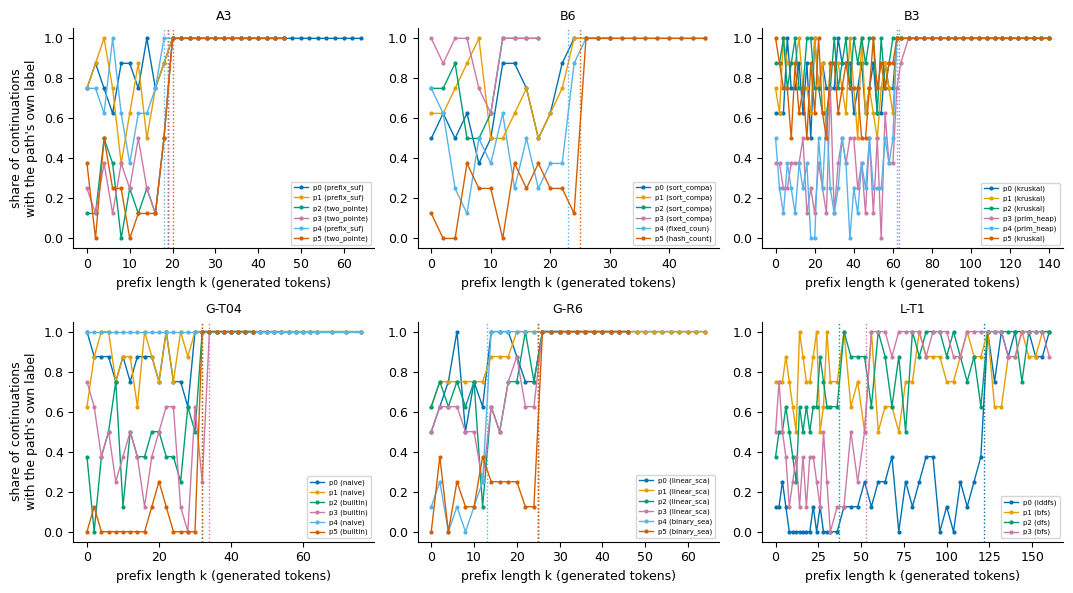

In [20]:
f1()

### F2: the decision tokens

For every committed opening: the template-averaged $T = 1$ probability of its 20 strongest decision tokens (log scale), coloured by $\hat P$(minority algorithm | token). Red tokens send the program to the T-1 minority algorithm, blue ones to the default; the dashed line marks the top-k 10 cut. A clean two-colour split with $H \approx 0$ means the token decides the algorithm. L-T1's mixed colours ($H$ = 0.63 bits) mean it does not.

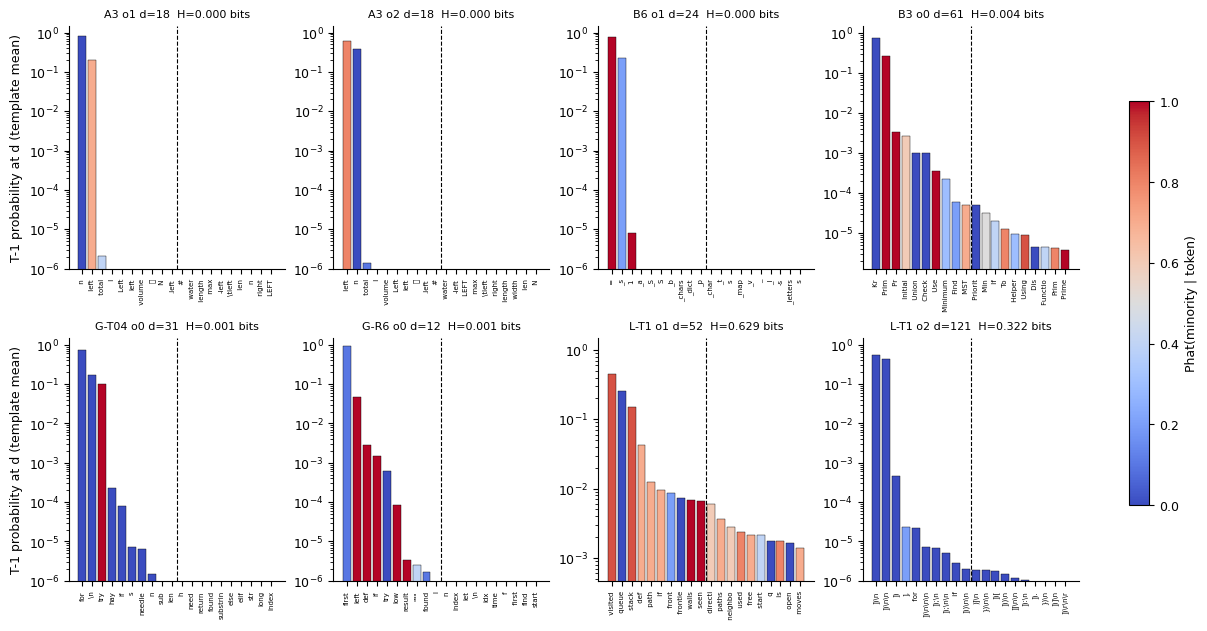

In [21]:
f2()

### F3: predicted vs observed share of the T-1 minority algorithm

Black points: the observed share of each unit's T-1 minority algorithm in the top-p 1 cells (N = 100, Wilson 95 % intervals). Lines: the law L (thick orange) and the four rivals, all committed before these samples existed. Where temperature matters (A3, B3, G-R6), the flat baseline B0 (grey) cannot follow the curve. On G-R6, dropping the second decision (B2) over-predicts binary search at low $T$ (MAE 0.051 vs 0.014 for L). On L-T1 the law predicts an almost flat DFS share and misses both ends.

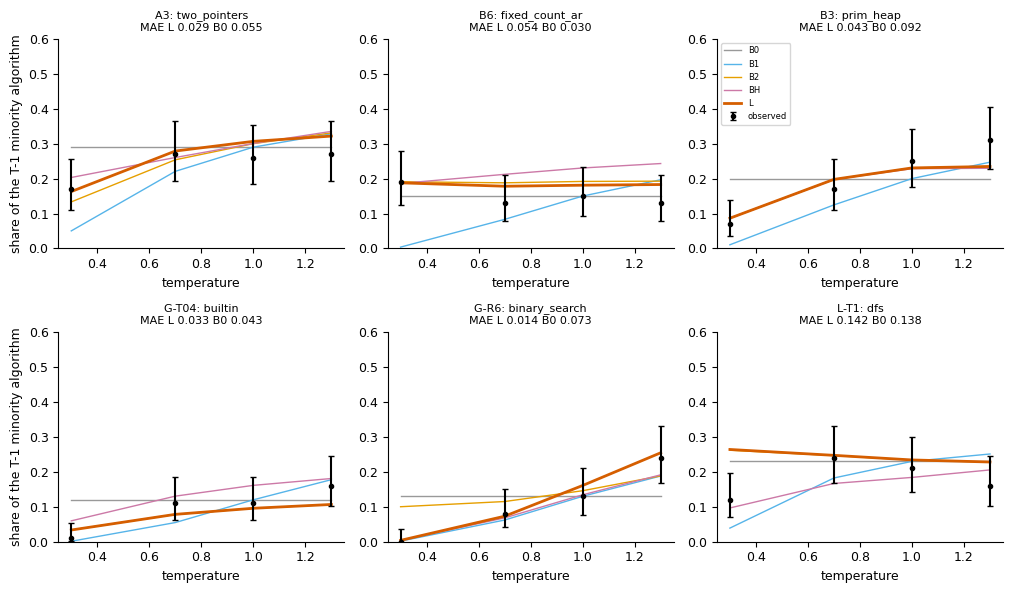

In [22]:
f3(an)

### F4: calibration, and F6: per-slot replay

**F4**: the law's predicted share against the observed share, for every (unit, temperature, algorithm) of the top-p 1 cells, coloured by model family. Points on the diagonal are perfectly calibrated predictions.

**F6, left**: on the curated slots that stay on a committed opening, how often replaying the slot's own uniforms through the teacher-forced decision distribution names the algorithm the slot actually wrote. With all 100 slots per cell, the full run gets 0.87 to 1.00 on the Qwen and Gemma units. L-T1 has no bar here: none of its curated slots stays on an opening (Llama's openings cover only about 2 % of programs). **F6, right**: per cell, the realisation gap (observed vs replay-implied shares, full N) against the mechanism gap (replay-implied vs the law). L-T1's cells (pink) are the ones far above the diagonal.

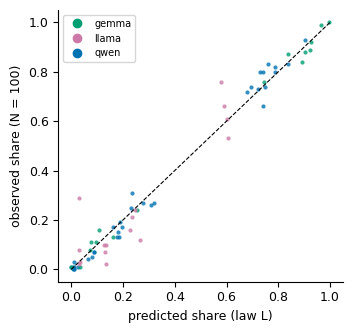

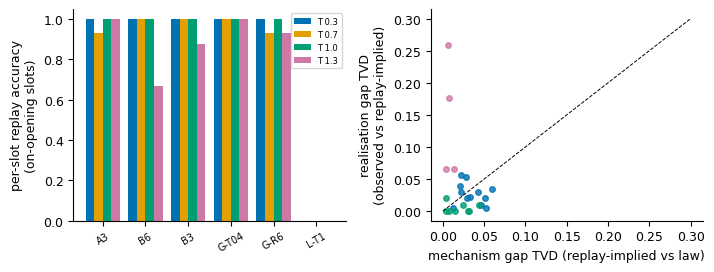

In [23]:
f4(an)
f6(an)

## 13. Results: the law against its rivals, and ideas vs phrasings

The first table collects the recomputed per-unit scores (top-p 1) with the pass criteria, next to the committed MAE of the law; the bar chart compares the law with its rivals (dashed line: the 0.10 pass threshold).

The second table and the stacked bars answer the motivating question: *does loosening the temperature add ideas, or only phrasings?* Each bar segment is one algorithm's share of the 100 programs in a cell, recomputed from the observed counts. The number inside a segment is how many **phrasing clusters** (AST 4-gram Jaccard ≥ 0.8) that algorithm's programs form in the full run. The table adds the effective number of correct algorithms (Hill-1, rarefied to 25 programs) and the phrasing clusters recomputed here on the 15 curated slots per unit (clusters / programs).

,model,held out,default -> T-1 minority,decision tokens,MAE L,MAE B0,MAE B1,MAE B2,MAE BH,H (bits),unit passes,committed MAE L
unit,,,,,,,,,,,,
A3,Qwen3-8B,False,prefix_suffix_max -> two_pointers,d=18: ' n' (prefix_suffix_max) vs ' left' (two...,0.029,0.055,0.070,0.038,0.037,0.0000,True,0.029
B6,Qwen3-8B,False,sort_compare -> fixed_count_array,d=24: ' =' (fixed_count_array) vs '_s' (hash_c...,0.054,0.030,0.091,0.054,0.071,0.0000,True,0.054
B3,Qwen3-8B,False,kruskal -> prim_heap,d=61: ' Kr' (kruskal) vs ' Prim' (prim_heap),0.043,0.092,0.058,0.043,0.045,0.0042,True,0.043
G-T04,gemma-3-4b-it,True,naive -> builtin,d=31: 'for' (naive) vs 'try' (builtin),0.033,0.043,0.023,0.033,0.036,0.0008,True,0.033
G-R6,gemma-3-4b-it,True,linear_scan -> binary_search,d=12: 'first' (linear_scan) vs 'left' (binary_...,0.014,0.073,0.018,0.051,0.017,0.0008,True,0.014
L-T1,Llama-3.1-8B-Instruct,True,bfs -> dfs,d=52: ' visited' (dfs) vs ' queue' (bfs); d=12...,0.142,0.138,0.143,0.142,0.134,0.6286,False,0.142


claim L: PARTIAL (held-out criterion underpowered: fewer than 4 held-out units scored)
  5/6 units pass, held-out 2/3; L beats B0 / B1 / B2 / BH on 4 / 5 / 3 / 5 of 6 units (one-sided sign test vs B0: p = 0.344)
committed verdict: PARTIAL (held-out criterion underpowered: fewer than 4 held-out units scored)


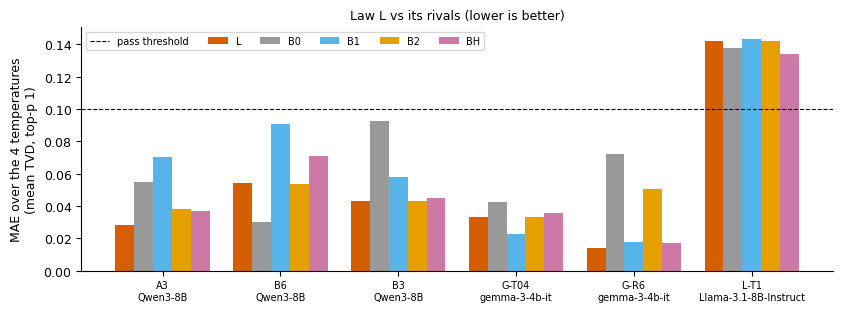

algorithms written  default share  minority share  \
unit  T                                                        
A3    0.3                   2           0.83            0.17   
      0.7                   2           0.73            0.27   
      1.0                   2           0.74            0.26   
      1.3                   2           0.72            0.27   
B6    0.3                   3           0.80            0.19   
      0.7                   3           0.83            0.13   
      1.0                   3           0.80            0.15   
      1.3                   3           0.80            0.13   
B3    0.3                   2           0.93            0.07   
      0.7                   2           0.82            0.17   
      1.0                   2           0.74            0.25   
      1.3                   2           0.66            0.31   
G-T04 0.3                   2           0.99            0.01   
      0.7                   2           0.89            0.11   
      1.0                   3           0.88            0.11   
      1.3                   2           0.84            0.16   
G-R6  0.3                   1           1.00            0.00   
      0.7                   2           0.92            0.08   
      1.0                   2           0.87            0.13   
      1.3                   2           0.76            0.24   
L-T1  0.3                   3           0.76            0.12   
      0.7                   3           0.66            0.24   
      1.0                   3           0.61            0.21   
      1.3                   3           0.53            0.16   

           Hill-1 (correct)  \
unit  T                       
A3    0.3              1.56   
      0.7              1.77   
      1.0              1.75   
      1.3              1.85   
B6    0.3              1.68   
      0.7              1.68   
      1.0              1.80   
      1.3              1.82   
B3    0.3              1.28   
      0.7              1.63   
      1.0              1.83   
      1.3              2.08   
G-T04 0.3              1.05   
      0.7              1.40   
      1.0              1.47   
      1.3              1.54   
G-R6  0.3              1.00   
      0.7              1.32   
      1.0              1.45   
      1.3              1.69   
L-T1  0.3              1.20   
      0.7              1.38   
      1.0              1.51   
      1.3              1.75   

                   phrasing clusters per algorithm (N = 100)  \
unit  T                                                        
A3    0.3                prefix_suffix_max 1, two_pointers 1   
      0.7                prefix_suffix_max 2, two_pointers 1   
      1.0                prefix_suffix_max 2, two_pointers 2   
      1.3                prefix_suffix_max 3, two_pointers 2   
B6    0.3  sort_compare 2, fixed_count_array 1, hash_count 1   
      0.7  sort_compare 2, fixed_count_array 2, hash_count 1   
      1.0  sort_compare 2, fixed_count_array 3, hash_count 2   
      1.3  sort_compare 2, fixed_count_array 4, hash_count 2   
B3    0.3                             kruskal 4, prim_heap 2   
      0.7                             kruskal 9, prim_heap 3   
      1.0                            kruskal 13, prim_heap 4   
      1.3                            kruskal 22, prim_heap 7   
G-T04 0.3                                 naive 1, builtin 1   
      0.7                                 naive 1, builtin 1   
      1.0                          naive 1, builtin 1, kmp 1   
      1.3                                 naive 2, builtin 1   
G-R6  0.3                                      linear_scan 2   
      0.7                     linear_scan 2, binary_search 3   
      1.0                     linear_scan 2, binary_search 4   
      1.3                     linear_scan 2, binary_search 8   
L-T1  0.3                             bfs 40, dfs 9, iddfs 8   
      0.7                            bfs 62, dfs 24, iddfs 7   
   

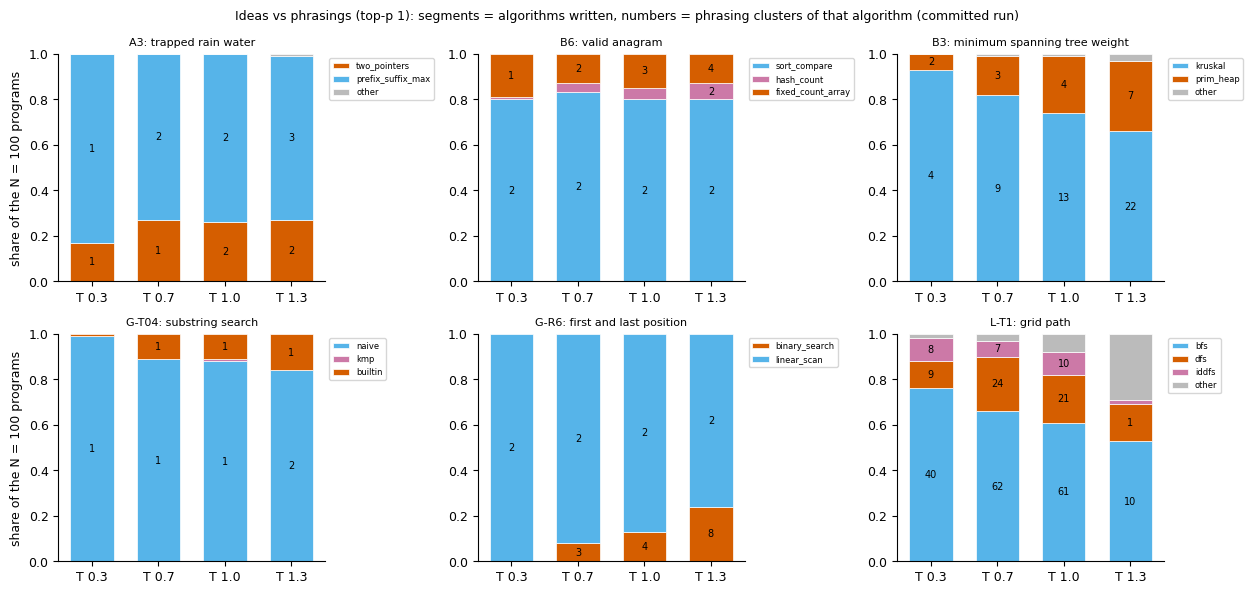

In [24]:
# ---- per-unit scores of the law and its rivals (recomputed in sections 7 to 11) ----
summ = []
for u, a in an["units"].items():
    loc = META["units"][u]["loc"]
    dec = []
    for o in loc["openings"]:          # per opening: the strongest decision token of each of the top two algorithms
        best: dict[str, tuple[float, str]] = {}
        for t, s, m in zip(o["tokens"], o["token_strs"], o["mass_T1"]):
            alg = a["bins"][int(np.argmax(o["phat"][str(t)]))]
            best[alg] = max(best.get(alg, (0.0, "")), (m, s))
        top = sorted(best.items(), key=lambda kv: -kv[1][0])[:2]
        dec.append(f"d={o['d']}: " + " vs ".join(f"{s!r} ({alg})" for alg, (m, s) in top))
    dec = "; ".join(dec)
    summ.append({"unit": u, "model": UNITS[u]["model_id"].split("/")[-1], "held out": a["held_out"],
                 "default -> T-1 minority": f"{a['default']} -> {a['minority']}", "decision tokens": dec,
                 **{f"MAE {m}": round(a["mae"]["p1"][m], 3) for m in ("L", "B0", "B1", "B2", "BH")},
                 "H (bits)": round(a["H_committed"], 4), "unit passes": a["pass"],
                 "committed MAE L": round(META["units"][u]["committed"]["mae"]["p1"]["L"], 3)})
display(pd.DataFrame(summ).set_index("unit"))
vv = an["verdict"]
print(f"claim L: {vv['status']}")
print(f"  {vv['n_pass']}/{vv['n_scored']} units pass, held-out {vv['n_heldout_pass']}/{vv['n_heldout_scored']};"
      " L beats B0 / B1 / B2 / BH on "
      + " / ".join(str(vv["L_vs_baselines"][m]["n_L_better"]) for m in ("B0", "B1", "B2", "BH"))
      + f" of {vv['n_scored']} units (one-sided sign test vs B0: p = {vv['holm_input_p_L_sign_test_vs_B0']:.3f})")
print("committed verdict:", META["committed_verdict"]["status"])

us = list(an["units"])
fig, ax = plt.subplots(figsize=(8.5, 3.2))
x = np.arange(len(us))
for i, m in enumerate(("L", "B0", "B1", "B2", "BH")):
    ax.bar(x + (i - 2) * 0.16, [an["units"][u]["mae"]["p1"][m] for u in us], 0.16, color=MCOL[m], label=m)
ax.axhline(THRESH["unit_mae_pass"], color="k", ls="--", lw=0.8, label="pass threshold")
ax.set_xticks(x)
ax.set_xticklabels([f"{u}\n{UNITS[u]['model_id'].split('/')[-1]}" for u in us], fontsize=7)
ax.set_ylabel("MAE over the 4 temperatures\n(mean TVD, top-p 1)")
ax.set_title("Law L vs its rivals (lower is better)", fontsize=9)
ax.legend(ncol=6, fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

# ---- ideas vs phrasings: how many algorithms are written, and in how many ways ----
ip = []
for u, a in an["units"].items():
    full = META["units"][u]["committed"]["phrasing"]       # all N = 100 programs of each cell (committed run)
    for T in TEMPS:
        pk = f"p1|{T}"
        c = a["cells"][pk]
        ip.append({"unit": u, "T": T,
                   "algorithms written": sum(c["counts"][b] > 0 for b in a["bins"] if b not in ("other", "invalid")),
                   "default share": c["shares"][a["bins"].index(a["default"])],
                   "minority share": c["shares"][a["bins"].index(a["minority"])],
                   "Hill-1 (correct)": round(c["hill1_correct"]["hill1"], 2),
                   "phrasing clusters per algorithm (N = 100)": ", ".join(
                       f"{b} {v['phrasing_clusters_j08']}" for b, v in sorted(full[pk].items(), key=lambda kv: -kv[1]["n"])),
                   "recomputed on curated slots (clusters/programs)": ", ".join(
                       f"{b} {v['phrasing_clusters_j08']}/{v['n']}"
                       for b, v in sorted(a["phrasing"][pk].items(), key=lambda kv: -kv[1]["n"]))})
display(pd.DataFrame(ip).set_index(["unit", "T"]))

n = len(us)
ncol = min(n, 3)
nrow = math.ceil(n / ncol)
fig, axs = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.0 * nrow), squeeze=False)
for ax, u in zip(axs.flat, us):
    a = an["units"][u]
    full = META["units"][u]["committed"]["phrasing"]
    bottom = np.zeros(len(TEMPS))
    for j, b in enumerate(a["bins"]):
        sh = np.array([a["cells"][f"p1|{T}"]["shares"][j] for T in TEMPS])
        if not sh.any():
            continue
        col = (MCOL["B1"] if b == a["default"] else MCOL["L"] if b == a["minority"] else
               "#BBBBBB" if b in ("other", "invalid") else ("#009E73", "#CC79A7", "#E69F00", "#F0E442")[j % 4])
        ax.bar(np.arange(len(TEMPS)), sh, 0.65, bottom=bottom, color=col, edgecolor="white", lw=0.5, label=b)
        for i, T in enumerate(TEMPS):
            k = full[f"p1|{T}"].get(b, {}).get("phrasing_clusters_j08")
            if k and sh[i] >= 0.07:
                ax.text(i, bottom[i] + sh[i] / 2, str(k), ha="center", va="center", fontsize=7)
        bottom += sh
    ax.set_xticks(np.arange(len(TEMPS)))
    ax.set_xticklabels([f"T {T}" for T in TEMPS])
    ax.set_ylim(0, 1)
    ax.set_title(f"{u}: {UNITS[u]['name']}", fontsize=8)
    ax.legend(fontsize=6, loc="upper left", bbox_to_anchor=(1.0, 1.0))
for ax in axs[:, 0]:
    ax.set_ylabel("share of the N = 100 programs")
for ax in axs.flat[n:]:
    ax.set_visible(False)
fig.suptitle("Ideas vs phrasings (top-p 1): segments = algorithms written, "
             "numbers = phrasing clusters of that algorithm (committed run)", fontsize=9)
plt.tight_layout()
plt.show()

## Takeaways

- **Temperature re-weights known ideas; it does not add new ones.** At every temperature each unit's programs implement 1 to 3 catalogue algorithms, plus a few `other` programs. The only additions with $T$ are known ones: G-R6's binary search appears above $T$ = 0.3, and G-T04 writes a single KMP program at $T$ = 1.0. Raising $T$ moves mass from the default algorithm to the second known one (B3: Prim 7 → 17 → 25 → 31 % of programs; G-R6: binary search 0 → 8 → 13 → 24 %) and multiplies the *phrasings* of each algorithm (B3: Kruskal 4 → 9 → 13 → 22 phrasing clusters). In the full run the novelty audit judged 0 of 4,703 correct programs novel (rule-of-three upper bound 0.0006).
- **The shift is predictable before sampling.** On 5 of 6 units, the model's own probabilities at one or two decision tokens predict the algorithm shares at all four temperatures with MAE 0.014 to 0.054 (N = 100 per cell). Examples: B3 `' Kr'` vs `' Prim'` at generated token 61; G-R6 `'first'` at 12, then `'for'` vs `'left'` at 24. The second decision matters on G-R6 (single-decision law B2: 0.051, law L: 0.014) and on A3.
- **Where it fails.** On L-T1 (Llama-3.1-8B, grid path) the decision is spread over many positions (H = 0.63 bits; the openings cover only about 2 % of programs), and at $T$ = 1.3, 72 of 100 programs hit the token cap. The law does no better than the flat baseline there (0.142 vs 0.138).
- **Against the rivals.** L beats the flat baseline B0 on 4 of 6 units (one-sided sign test p = 0.34) and B1 / BH on 5 of 6. The held-out criterion is underpowered (3 held-out units scored, 4 required).
- **Scaling back to the full experiment.** The CPU-side sizes in the configuration cell are already the original values. The GPU stages (`python method.py all` in the experiment folder: sampling, the locator, teacher forcing and the sweep) need a CUDA GPU with at least 20 GB, the four model checkpoints and about 5 hours; the experiment's `reproducibility.md` lists every command.